# Stage 1 WP3 — Open Models 지식그래프 구축

| | |
|---|---|
| **Work package** | WP3 — Knowledge Graph Construction (Stage 1의 마지막 단계) |
| **Track** | Open Models |
| **입력** | WP2 entity·relation·co-occurrence handover, WP3 relation correction 결과 |
| **상태** | 그래프 구축 완료, Tier B relation 사람 검수 대기 |

과제 안내서의 Stage 1 *Knowledge Graph Construction* 요구사항과 이 notebook의 대응은 다음과 같다.

| 요구사항 | 절 |
|---|---|
| graph 전에 compact topic-specific schema 정의 | 5 |
| node = entity, edge = co-mention 또는 extracted relation | 6 |
| centrality·clustering 등 network metric으로 영향력 있는 entity와 새로운 관계 분석 | 7–10 |
| NetworkX·Graphviz 시각화 | 11 |
| Stage 3에서 다시 쓸 graph와 schema 저장 | 14–15 |
| topic-focused KG와 short schema/data dictionary, 주요 insight 문서화 | 12–14 |

```
WP2 handover (수정하지 않음)
  → 2. 입력 검증
  → 3. relation 보정 결과 (stage1_wp3_relation_correction.ipynb)
  → 3-1. 속성·계보 관계 보강 (관계 기준 type, 규칙 기반 속성, 보조 층)
  → 4–6. 검수 규칙 · compact schema · graph 생성
  → 7–10. 구조 · 중심성 · community · 시간 분석
  → 11–13. 시각화 · insight · 한계
  → 14–15. 저장 · Stage 3 연결 검증
```

## 1. 실행 환경과 입력 경로

입력은 세 곳에서 읽는다. WP1 `open_models_core.parquet`은 선택 입력으로, 있으면 문서 범위 검증과 기사
제목·URL 연결에 사용한다.

- `outputs/stage1_wp2_open_models_official_20261007/`: 공식 WP2 handover (수정하지 않음)
- `outputs/stage1_wp3_relation_correction_20261008/`: relation correction notebook 산출물
- `artifacts/stage1_wp3/evaluation/relation_correction/`: 사람 검수용 Tier B 표본

대용량 결과는 Git-ignored `outputs/stage1_wp3_knowledge_graph_ko/`에, 작은 파일은 `artifacts/stage1_wp3/final_ko/`에
저장한다. 영어 최종본(`stage1_wp3_knowledge_graph.ipynb`)의 결과와 섞이지 않도록 폴더를 분리했다.

In [1]:
from datetime import datetime, timezone
from pathlib import Path
import hashlib
import json
import re
import sys

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

ROOT = Path.cwd()
if not (ROOT / "config").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from stage3_graph_rag import GraphEvidenceRetriever
from wp3_knowledge_graph.pipeline import (
    build_relation_type_summary,
    calculate_node_metrics,
    calculate_relation_type_metrics,
    collapse_relations,
    detect_cooccurrence_communities,
    graph_summary,
)

WP2_INPUT_DIR = ROOT / "outputs" / "stage1_wp2_open_models_official_20261007"
CORRECTION_DIR = ROOT / "outputs" / "stage1_wp3_relation_correction_20261008"
CORRECTED_REVIEW_PATH = (
    ROOT / "artifacts" / "stage1_wp3" / "evaluation" / "relation_correction"
    / "relation_review_corrected_seed2026.xlsx"
)
SUPPLEMENT_REVIEW_PATH = (
    ROOT / "artifacts" / "stage1_wp3" / "evaluation" / "relation_correction"
    / "relation_review_supplement_seed2026.xlsx"
)
LEXICON_PATH = ROOT / "artifacts" / "stage1_wp1" / "lexicon" / "open_models_lexicon.json"
COMPACT_SCHEMA_PATH = ROOT / "config" / "wp3_compact_schema.json"
WP1_CORE_PATH = ROOT / "dataset" / "processed" / "open_models_core.parquet"  # 선택: 문서 범위 검증, 기사 제목·URL
FINAL_OUTPUT_DIR = ROOT / "outputs" / "stage1_wp3_knowledge_graph_ko"
FINAL_ARTIFACT_DIR = ROOT / "artifacts" / "stage1_wp3" / "final_ko"
FIGURE_DIR = FINAL_ARTIFACT_DIR / "figures"
for directory in [FINAL_OUTPUT_DIR, FIGURE_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

MIN_COOCCURRENCE_DOCUMENTS = 2   # 6절의 threshold 비교 참고
DRAW_COOCCURRENCE_DOCUMENTS = 5  # community 그림에서만 쓰는 더 높은 기준
SEED = 42
PERIODS = {"P1 (2024-09~2025-08)": ("2024-09-01", "2025-08-31"),
           "P2 (2025-09~2026-08)": ("2025-09-01", "2026-08-31")}

for required_path in [WP2_INPUT_DIR, CORRECTION_DIR, CORRECTED_REVIEW_PATH, COMPACT_SCHEMA_PATH]:
    assert required_path.exists(), f"필수 입력이 없습니다: {required_path}"

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

def save_figure(fig, filename):
    # The WP3 pipeline module uses the non-interactive Agg backend, so saved PNGs are displayed instead.
    path = FIGURE_DIR / filename
    fig.savefig(path, dpi=160, bbox_inches="tight")
    plt.close(fig)
    display(Image(filename=str(path)))

def pretty(label):
    return str(label).replace("_", " ")

## 2. WP2 인계 데이터 검증

graph를 만들기 전에 WP2 handover가 완전하고 서로 연결되는지 확인한다. 원본 파일은 수정하지 않는다.

- 필요한 파일이 모두 있는가
- node ID와 문장 ID(`doc_id` + 문서 안의 `sentence_id`)가 고유한가
- 모든 relation 근거 문장이 `sentences.csv`에 있고, 모든 relation endpoint가 node table에 있는가
- WP1 핵심 문서 집합과 WP2 기사 집합이 같은가 (WP1 parquet이 있을 때)

In [2]:
WP2_FILES = ["nodes.csv", "nodes_quarterly.csv", "entity_mentions.csv", "sentences.csv", "edges_relations.csv",
             "relations_evidence.csv", "edges_cooccurrence.csv", "schema.json"]
missing_files = [name for name in WP2_FILES if not (WP2_INPUT_DIR / name).exists()]
assert not missing_files, f"WP2 파일이 없습니다: {missing_files}"

wp2_nodes = pd.read_csv(WP2_INPUT_DIR / "nodes.csv", keep_default_na=False, na_values=[""])
wp2_edges = pd.read_csv(WP2_INPUT_DIR / "edges_relations.csv")
wp2_evidence = pd.read_csv(WP2_INPUT_DIR / "relations_evidence.csv")
wp2_cooccurrence = pd.read_csv(WP2_INPUT_DIR / "edges_cooccurrence.csv")
nodes_quarterly = pd.read_csv(WP2_INPUT_DIR / "nodes_quarterly.csv")
sentences = pd.read_csv(WP2_INPUT_DIR / "sentences.csv")
wp2_schema = json.loads((WP2_INPUT_DIR / "schema.json").read_text(encoding="utf-8"))

glirel_evidence = wp2_evidence[wp2_evidence["source"] == "glirel"]
sentence_keys = set(zip(sentences["doc_id"], sentences["sentence_id"]))
evidence_keys = set(zip(glirel_evidence["doc_id"], glirel_evidence["sentence_id"].astype(int)))
node_ids = set(wp2_nodes["entity_id"])
endpoints = set(wp2_evidence["head_id"]) | set(wp2_evidence["tail_id"])
if WP1_CORE_PATH.exists():
    wp1_doc_ids = set(pd.read_parquet(WP1_CORE_PATH, columns=["doc_id"])["doc_id"])
    lineage = ("PASS" if wp1_doc_ids == set(sentences["doc_id"]) else "FAIL", f"WP1 {len(wp1_doc_ids):,}개 문서")
else:
    lineage = ("SKIP", "WP1 parquet 없음")

input_checks = pd.DataFrame(
    [
        ("WP2 인계 파일", "PASS", f"{len(WP2_FILES)}개 파일"),
        ("node ID 고유", "PASS" if wp2_nodes["entity_id"].is_unique else "FAIL", f"{len(wp2_nodes):,}개 node"),
        ("문장 ID 고유", "PASS" if len(sentence_keys) == len(sentences) else "FAIL",
         f"{len(sentences):,}개 문장 / {sentences['doc_id'].nunique():,}개 기사"),
        ("relation 근거 문장이 sentences에 있음", "PASS" if evidence_keys <= sentence_keys else "FAIL",
         f"GLiREL 근거 {len(glirel_evidence):,}행"),
        ("relation endpoint가 node table에 있음", "PASS" if endpoints <= node_ids else "FAIL",
         f"{wp2_edges['source'].value_counts().to_dict()}"),
        ("WP1 핵심 문서 = WP2 기사", *lineage),
        ("WP2 schema 범위", "INFO", f"entity type {len(wp2_schema['node']['entity_types'])}개, "
         f"relation type {len(wp2_schema['edges']['relation']['types'])}개"),
    ],
    columns=["검사", "결과", "내용"],
)
display(input_checks)
assert not input_checks["결과"].eq("FAIL").any()

,검사,결과,내용
0,WP2 인계 파일,PASS,8개 파일
1,node ID 고유,PASS,"54,597개 node"
2,문장 ID 고유,PASS,"99,438개 문장 / 1,210개 기사"
3,relation 근거 문장이 sentences에 있음,PASS,"GLiREL 근거 30,560행"
4,relation endpoint가 node table에 있음,PASS,"{'glirel': 22957, 'wp1_lexicon': 35}"
5,WP1 핵심 문서 = WP2 기사,SKIP,WP1 parquet 없음
6,WP2 schema 범위,INFO,"entity type 20개, relation type 36개"


## 3. relation 보정이 필요한 이유와 결과

WP2는 recall을 위해 넓은 schema(entity type 20개, relation type 36개)로 GLiREL relation을 추출했고, relation
정확도는 평가하지 않았다. WP3에서 relation 90개 표본을 검토한 결과(AI 1차 판정이며 공식 사람 검수가 아님)
precision은 약 0.47이었고, 오류는 대부분 관계 추출보다 entity 단계에서 생겼다.

- **일반명사 node**: `model`, `company`, `AI models`, `GPUs`가 relation의 head·tail이 됨
- **잘못된 연결**: WP1 regex가 "Llama Nemotron"의 Llama도 Llama family로 잡아 `Llama → developed by → NVIDIA`(42문장)가 생김.
  나열 문장에서 엉뚱한 쌍이 연결됨 (예: Gemma → developed by → Microsoft)
- **별칭·type 오류**: `Ai2` / `Allen Institute for AI`가 다른 node이고, `Alibaba`가 장소로 분류됨

score threshold로 거르면 맞는 relation도 함께 사라지므로, `notebooks/stage1_wp3_relation_correction.ipynb`에서
오류 원인별 규칙으로 보정했다.

1. 이름 변형·별칭 병합, node type 수정, 규칙 기반 일반명사 node 표시
2. 다른 제품명 안의 family 이름(Llama Nemotron, Llama Stack) 연결 해제
3. WP1 lexicon 개발사와 충돌하는 `developed by`, 자기 회사 제품과의 `competes with`, 양방향 중복 제외
4. 같은 문장 반복을 제거한 뒤 서로 다른 근거 문장 수 계산

보정 결과 각 relation은 **Tier A**(WP1 lexicon model family → developer), **Tier B**(모든 검사 통과 + 서로
다른 근거 문장 2개 이상), **C**(근거 1개), **X**(제외)로 분류된다. 지식그래프에는 A와 B를 사용하고, C와 X는
삭제하지 않고 사유와 함께 보정 산출물에 남긴다.

In [3]:
nodes_corrected = pd.read_csv(
    CORRECTION_DIR / "nodes_corrected.csv", keep_default_na=False, na_values=[""]
)
edges_corrected = pd.read_csv(CORRECTION_DIR / "edges_relations_corrected.csv")
graph_candidates = pd.read_csv(CORRECTION_DIR / "edges_graph_candidates.csv")
evidence_corrected = pd.read_csv(CORRECTION_DIR / "relations_evidence_corrected.csv")
compact_schema = json.loads(COMPACT_SCHEMA_PATH.read_text(encoding="utf-8"))

glirel_raw = wp2_edges[wp2_edges["source"] == "glirel"]
relation_funnel = pd.DataFrame(
    [
        ("WP2 GLiREL 원본 triple", len(glirel_raw)),
        ("WP2 권장 필터: type_valid & 문장 2개 이상", int((glirel_raw["type_valid"] & (glirel_raw["n_sentences"] >= 2)).sum())),
        ("보정 후 Tier B: 모든 검사 통과 & 서로 다른 문장 2개 이상", int((edges_corrected["tier"] == "B").sum())),
        ("Tier A: WP1 lexicon model family → developer", int((edges_corrected["tier"] == "A").sum())),
        ("최종 graph 후보: Tier A+B, 동일 triple 병합", len(graph_candidates)),
    ],
    columns=["단계", "triple 수"],
)
display(relation_funnel)

exclusion_reasons = (
    edges_corrected["exclusion_reason"].dropna().str.split(";").explode()
    .value_counts().rename_axis("제외 사유").reset_index(name="triple 수")
)
display(exclusion_reasons)
display(graph_candidates["sources"].value_counts().rename_axis("출처").reset_index(name="triple 수"))

,단계,triple 수
0,WP2 GLiREL 원본 triple,22957
1,WP2 권장 필터: type_valid & 문장 2개 이상,1629
2,보정 후 Tier B: 모든 검사 통과 & 서로 다른 문장 2개 이상,1049
3,Tier A: WP1 lexicon model family → developer,33
4,"최종 graph 후보: Tier A+B, 동일 triple 병합",1067


,제외 사유,triple 수
0,type_invalid,9155
1,generic_node,6876
2,conflicts_lexicon_developer,438
3,reverse_duplicate,223
4,own_product_or_parent,92


,출처,triple 수
0,glirel,1034
1,wp1_lexicon,18
2,glirel | wp1_lexicon,15


WP2 권장 필터의 1,629개 대신 1,067개 triple을 사용한다. 줄어든 이유는 점수 threshold가 아니라 구체적인
오류 원인이다. 가장 큰 제외 사유는 schema type 위반과 `model`, `company`, `AI` 같은 일반명사 node다.

## 3-1. 속성·계보 관계 보강

보정 후 graph에는 계보(`based on`, `distilled from` 등), 속성(파라미터 수, context window, capability),
학습(학습 데이터·하드웨어) 관계가 거의 남지 않았다. 원인과 대응은 다음과 같다. 모두 WP2 산출물을 수정하지 않고
WP3에서 처리한다.

| 원인 | 대응 |
|---|---|
| `DeepSeek`, `Mistral`처럼 회사명과 모델명이 같은 WP1 family node가 회사 type으로 분류되어, 모델 관계가 schema type 검사에서 제외됨 | **관계 기준 type 판단**: WP1 family node가 모델 자리에 오면 모델로 보고 type을 다시 검사 |
| 파라미터 수가 `70B`, `70 billion parameters` 등 서로 다른 문자열 node라 같은 관계가 반복되지 않아 항상 근거 1개(Tier C) | **규칙 기반 속성 추출**: 문장에서 모델명 바로 뒤의 크기(`Llama 3.1 405B`)나 `N billion parameters`, `128K context`를 숫자로 정규화한다 |
| WP1 lexicon이 Qwen2.5·Qwen3 등을 `Qwen` 하나로 묶어, 크기가 family에 붙으면 "Qwen의 파라미터 수가 1.7B"처럼 부정확해짐 | **모델 단위 node**: 원문 이름에서 `Qwen3 1.7B`, `Llama 4 Scout` 같은 모델 node를 만들어 값을 붙이고 `member of family`로 family에 연결한다. 이름에 버전이 없으면 family node에 남기고 `family_level`로 표시한다 |
| 계보·속성·학습 관계는 근거 문장 2개 조건(Tier B)을 거의 넘지 못함 | **보조 층**: 이 세 그룹의 Tier C(근거 1개) relation을 graph에 포함하고 `tier = C`로 구분 |

새로 graph에 들어간 relation은 별도 검수 표본(`relation_review_supplement_seed2026.xlsx`)으로 사람이 확인한다.
표본 비율은 기존 Tier B 표본 비율보다 조금 높게 잡았다. 결과를 원문과 대조하다 확인한 명백한 오류 4개는
`MANUAL_EXCLUSIONS`에 사유와 함께 적어 graph에서 제외했다.

In [4]:
REL_TYPES = wp2_schema["edges"]["relation"]["types"]
PREDICATE_GROUP = compact_schema["predicate_group_mapping"]
MODEL_TYPES = ("FOUNDATION_MODEL", "AI_MODEL")
lexicon = json.loads(LEXICON_PATH.read_text(encoding="utf-8"))
family_ids = set(nodes_corrected.loc[nodes_corrected["canonical_id"].isin(lexicon["families"]), "entity_id"])
TRIPLE = ["head_id", "relation", "tail_id"]

def type_ok(relation, head_type, tail_type):
    spec = REL_TYPES.get(relation)
    if spec is None:
        return False
    forward = head_type in spec["head_types"] and tail_type in spec["tail_types"]
    backward = tail_type in spec["head_types"] and head_type in spec["tail_types"]
    return forward or (relation == "competes with" and backward)

def role_types(row):
    # WP1 family node는 모델 자리에 오면 FOUNDATION_MODEL로 본다. 원래 type으로 유효하면 그대로 둔다.
    heads = [row.head_type] + (["FOUNDATION_MODEL"] if row.head_id in family_ids and row.head_type not in MODEL_TYPES else [])
    tails = [row.tail_type] + (["FOUNDATION_MODEL"] if row.tail_id in family_ids and row.tail_type not in MODEL_TYPES else [])
    for head_type in heads:
        for tail_type in tails:
            if type_ok(row.relation, head_type, tail_type):
                return head_type, tail_type
    return None

# 1) 관계 기준 type 판단: type 위반만으로 제외된 relation을 다시 검사
type_only = edges_corrected[edges_corrected["exclusion_reason"].fillna("") == "type_invalid"].copy()
retyped = [role_types(row) for row in type_only.itertuples(index=False)]
role_typed = type_only[[r is not None for r in retyped]].copy()
role_typed[["head_type", "tail_type"]] = [r for r in retyped if r is not None]
role_typed["tier"] = np.where(role_typed["n_distinct_sentences"] >= 2, "B", "C")
role_typed["exclusion_reason"] = ""
existing = set(map(tuple, graph_candidates[TRIPLE].values))
role_typed = role_typed[[(t, r, h) not in existing or r == "competes with"
                         for h, r, t in role_typed[TRIPLE].values]]  # 반대 방향이 이미 graph에 있으면 제외

# 2) 보조 층: 계보·속성·학습 그룹의 Tier C (파라미터 수·context window는 아래 규칙 기반 추출로 대체)
FOCUS_GROUPS = {"LINEAGE", "ATTRIBUTE", "TRAINING"}
RULE_RELATIONS = {"has parameter count", "has context window"}
single_sentence = pd.concat([edges_corrected[edges_corrected["tier"] == "C"], role_typed[role_typed["tier"] == "C"]])
single_sentence = single_sentence[single_sentence["relation"].map(PREDICATE_GROUP).isin(FOCUS_GROUPS)
                                  & ~single_sentence["relation"].isin(RULE_RELATIONS)]

new_relations = pd.concat([
    role_typed[role_typed["tier"] == "B"].assign(sources="glirel", added_by="role_typed_tier_B"),
    single_sentence.assign(sources="glirel", added_by="single_sentence_layer"),
], ignore_index=True).drop_duplicates(TRIPLE)
new_relations = new_relations[[tuple(k) not in existing for k in new_relations[TRIPLE].values]]
display(new_relations.groupby(["added_by", "relation"]).size().rename("triple 수").reset_index()
        .sort_values(["added_by", "triple 수"], ascending=[True, False]))

,added_by,relation,triple 수
4,role_typed_tier_B,outperforms,17
0,role_typed_tier_B,available on,2
1,role_typed_tier_B,based on,2
3,role_typed_tier_B,licensed under,2
5,role_typed_tier_B,runs on,2
2,role_typed_tier_B,has capability,1
6,role_typed_tier_B,supported by,1
7,role_typed_tier_B,used by,1
10,single_sentence_layer,has capability,70
8,single_sentence_layer,based on,33


In [5]:
# 3) 규칙 기반 속성 추출: 파라미터 수와 context window를 모델(버전·크기) 단위로 연결
MATCH_MAP = str.maketrans({"‐": "-", "‑": "-", "‒": "-", "–": "-", "−": "-", "‘": "'", "’": "'", "“": '"', "”": '"'})
FAMILY_RX = {fid: re.compile(f["rx"]) for fid, f in lexicon["families"].items()}
family_node = (nodes_corrected[nodes_corrected["canonical_id"].isin(lexicon["families"])]
               .set_index("canonical_id")["entity_id"])
SIZE_AFTER_NAME = re.compile(r"^(?P<prefix>[\s\-]*(?:[A-Za-z]{0,10}[\d.]*[\s\-]*){0,2}?)(?P<num>\d+(?:\.\d+)?)\s?(?P<unit>[BbTt])(?![\w])")
PARAMETER_TEXT = re.compile(r"(?P<num>\d+(?:\.\d+)?)\s*(?P<unit>billion|trillion|[BT])\b[\s\-]*(?:total\s+)?param", re.I)
CONTEXT_TEXT = re.compile(r"(?P<num>\d+(?:\.\d+)?)\s*(?P<unit>[KkM]|million|thousand)\b[\s\-]*(?:token|context)", re.I)
COMPARISON = re.compile(r"\b(?:than|outperform\w*|compared|versus|vs\.?|rival\w*|beat\w*|like|such as)\b", re.I)
NEAR_CHARS = 50  # 숫자는 family 이름 뒤 50자 이내에 있어야 그 family의 값으로 본다

def nearest_family(spans, position, view):
    # 숫자 바로 앞(50자 이내)에 있고 사이에 비교 표현이 없는 family 언급 위치를 돌려준다
    candidates = [(start, end) for start, end in spans
                  if 0 <= position - end <= NEAR_CHARS and not COMPARISON.search(view[end:position])]
    return max(candidates, key=lambda span: span[1]) if candidates else None

def model_name_before(view, start, position):
    # family 언급부터 숫자 앞까지 이어지는 이름 토큰: "Llama 4 Scout has 109 billion" -> "Llama 4 Scout"
    tokens = []
    for token in view[start:position].split():
        token = re.sub(r"'s$", "", token.strip(",;:()"))
        if not re.match(r"^[A-Z0-9][\w.\-]*$", token):
            break
        tokens.append(token)
    return " ".join(tokens)

attribute_rows = []
for doc_id, sentence_id, text in zip(sentences["doc_id"], sentences["sentence_id"], sentences["sentence_text"]):
    view = str(text).translate(MATCH_MAP)
    hits = [(fid, m) for fid, rx in FAMILY_RX.items() if fid in family_node.index for m in rx.finditer(view)]
    if not hits:
        continue
    for fid, m in hits:  # 모델명 바로 뒤의 크기: "Llama 3.1 405B", "Qwen2.5-72B"
        size = SIZE_AFTER_NAME.match(view[m.end():m.end() + 30])
        if size and not re.search(r"\d\s?x\s?$", size["prefix"]):  # MoE 표기(8x22B) 제외
            value = float(size["num"]) * (1000 if size["unit"] in "Tt" else 1)
            surface = (m.group() + view[m.end():m.end() + size.end()]).strip()
            attribute_rows.append((fid, "has parameter count", value, surface, surface, "name_suffix", doc_id, sentence_id, text))
    if len({fid for fid, _ in hits}) == 1:  # 한 family만 나온 문장에서 family 이름 바로 뒤의 서술형 표현
        fid = hits[0][0]
        spans = [(m.start(), m.end()) for _, m in hits]
        matches = [("has parameter count", p) for p in PARAMETER_TEXT.finditer(view)
                   # "37B parameters activated": param 뒤에 eters가 먼저 오므로 \w*로 건너뛴 뒤 active를 확인한다
                   if not re.match(r"\w*\s*(?:active|activated)", view[p.end():p.end() + 20])]
        if re.search(r"context|window", view, re.I):
            matches += [("has context window", c) for c in CONTEXT_TEXT.finditer(view)]
        for relation, match in matches:
            span = nearest_family(spans, match.start(), view)
            if span is None:
                continue
            unit = match["unit"].lower()
            if relation == "has parameter count":
                value = float(match["num"]) * (1000 if unit.startswith("t") else 1)
            else:
                value = float(match["num"]) * (1_000_000 if unit in ("m", "million") else 1000)
            name = model_name_before(view, span[0], match.start())
            attribute_rows.append((fid, relation, value, match.group(), name, "single_family_sentence", doc_id, sentence_id, text))

doc_dates = (pd.read_csv(WP2_INPUT_DIR / "entity_mentions.csv", usecols=["doc_id", "date"])
             .drop_duplicates("doc_id").set_index("doc_id")["date"])
attribute_evidence = (pd.DataFrame(attribute_rows, columns=["family", "relation", "value", "surface", "model_text", "rule",
                                                            "doc_id", "sentence_id", "sentence_text"])
                      .drop_duplicates(["family", "relation", "value", "doc_id", "sentence_id"]))
attribute_evidence["family_id"] = attribute_evidence["family"].map(family_node)
attribute_evidence["date"] = attribute_evidence["doc_id"].map(doc_dates)
attribute_evidence["sentence_key"] = attribute_evidence["sentence_text"].map(lambda s: re.sub(r"\W+", " ", str(s).lower()).strip())

# 모델 이름 정규화: "Qwen 2.5 7B", "Qwen2.5-7B"는 같은 모델. family 이름만 있으면 family node에 남긴다(family_level)
family_label = nodes_corrected.set_index("entity_id")["entity"]
def model_label(text):
    name = re.sub(r"\s+", " ", str(text)).strip()
    return re.sub(r"(\d+(?:\.\d+)?)\s?([BbTt])$", lambda m: m.group(1) + m.group(2).upper(), name)
def model_key(label):
    return re.sub(r"[^0-9a-z.]", "", label.lower())
attribute_evidence["model_label"] = attribute_evidence["model_text"].map(model_label)
attribute_evidence["model_key"] = attribute_evidence["model_label"].map(model_key)
family_keys = {model_key(name) for name in family_label[list(family_node.values)]}
attribute_evidence["family_level"] = (attribute_evidence["model_key"].eq("")
                                      | attribute_evidence["model_key"].isin(family_keys)
                                      | attribute_evidence["model_key"].eq(attribute_evidence["family"].str.replace("_", "")))
display_label = (attribute_evidence[~attribute_evidence["family_level"]]
                 .groupby("model_key")["model_label"].agg(lambda x: x.value_counts().index[0]))
attribute_evidence["head_id"] = np.where(attribute_evidence["family_level"], attribute_evidence["family_id"],
                                         "model:variant_" + attribute_evidence["model_key"].str.replace(".", "_"))
attribute_evidence["head"] = np.where(attribute_evidence["family_level"], attribute_evidence["family_id"].map(family_label),
                                      attribute_evidence["model_key"].map(display_label))

def spec_node(relation, value):
    if relation == "has parameter count":
        return f"spec:params_{value:g}b", f"{value:g}B parameters"
    return f"spec:context_{value / 1000:g}k", (f"{value / 1_000_000:g}M-token context" if value >= 1_000_000
                                              else f"{value / 1000:g}K-token context")
attribute_evidence[["tail_id", "tail"]] = [spec_node(r, v) for r, v in zip(attribute_evidence["relation"], attribute_evidence["value"])]

def aggregate(evidence):
    return (evidence.groupby(TRIPLE)
            .agg(head=("head", "first"), tail=("tail", "first"), n_sentences=("sentence_key", "size"),
                 n_distinct_sentences=("sentence_key", "nunique"), n_docs=("doc_id", "nunique"),
                 first_seen=("date", "min"), last_seen=("date", "max"), family_level=("family_level", "first"))
            .reset_index())
attribute_relations = aggregate(attribute_evidence)
attribute_relations = attribute_relations[attribute_relations["n_distinct_sentences"] >= 2].assign(
    head_type="FOUNDATION_MODEL", tail_type="MODEL_SPEC", type_valid=True, tier="B", exclusion_reason="",
    sources="rule_attribute", added_by="rule_attribute")

# 모델 node를 family에 연결: "Qwen3 1.7B -> member of family -> Qwen" (근거는 같은 문장들)
variants = attribute_relations.loc[~attribute_relations["family_level"], "head_id"].unique()
member_evidence = (attribute_evidence[attribute_evidence["head_id"].isin(variants)]
                   .assign(relation="member of family", tail_id=lambda d: d["family_id"],
                           tail=lambda d: d["family_id"].map(family_label)))
member_relations = aggregate(member_evidence).assign(
    head_type="FOUNDATION_MODEL", tail_type="FOUNDATION_MODEL", type_valid=True, tier="B", exclusion_reason="",
    sources="rule_attribute", added_by="rule_family_member")
attribute_evidence = pd.concat([attribute_evidence, member_evidence], ignore_index=True)

# 새 node: 모델(버전·크기) node와 값 node
new_nodes = (attribute_evidence[attribute_evidence["head_id"].isin(variants)]
             .groupby("head_id").agg(entity=("head", "first"), mentions=("sentence_key", "size"), n_docs=("doc_id", "nunique"),
                                     first_seen=("date", "min"), last_seen=("date", "max"), family_id=("family_id", "first"))
             .reset_index().rename(columns={"head_id": "entity_id"}).assign(entity_type="FOUNDATION_MODEL"))
spec_ids = set(attribute_relations["tail_id"])
spec_nodes = (attribute_evidence[attribute_evidence["tail_id"].isin(spec_ids)]
              .groupby("tail_id").agg(entity=("tail", "first"), mentions=("sentence_key", "size"),
                                      n_docs=("doc_id", "nunique"), first_seen=("date", "min"), last_seen=("date", "max"))
              .reset_index().rename(columns={"tail_id": "entity_id"}).assign(entity_type="MODEL_SPEC"))
added_nodes = pd.concat([new_nodes, spec_nodes], ignore_index=True).assign(
    merged_ids=lambda d: d["entity_id"], n_merged=1, is_generic=False)
nodes_corrected = pd.concat([nodes_corrected, added_nodes[~added_nodes["entity_id"].isin(nodes_corrected["entity_id"])]],
                            ignore_index=True)

# family node에는 그 family의 모델들에서 관찰된 값 목록을 붙인다 (어느 모델의 값인지는 모델 node에 있음)
for column, relation in [("parameter_sizes_b", "has parameter count"), ("context_windows_tokens", "has context window")]:
    graph_values = attribute_relations[attribute_relations["relation"] == relation][TRIPLE]
    values = (attribute_evidence.merge(graph_values, on=TRIPLE)
              .groupby("family_id")["value"].apply(lambda v: json.dumps(sorted(set(v)))))
    nodes_corrected[column] = nodes_corrected["entity_id"].map(values).fillna("")

new_relations = pd.concat([new_relations, attribute_relations, member_relations], ignore_index=True)
graph_candidates = pd.concat([graph_candidates.assign(added_by="correction"), new_relations], ignore_index=True)
assert not graph_candidates.duplicated(TRIPLE).any()

# 결과를 원문과 대조하다 확인한 명백한 오류는 사유와 함께 제외한다
MANUAL_EXCLUSIONS = [  # head_id, relation, tail_id, reason
    ("org:anthropic", "headquartered in", "place:china", "Anthropic은 미국 회사; 중국 관련 문장에서 잘못 추출"),
    ("technology:hugging_face", "developed by", "org:google_deepmind", "모델을 Hugging Face에 공개했다는 문장; 개발 관계 아님"),
    ("technology:hugging_face", "developed by", "org:nvidia", "모델을 Hugging Face에 공개했다는 문장; 개발 관계 아님"),
    ("technology:hugging_face", "developed by", "org:openai", "모델을 Hugging Face에 공개했다는 문장; 개발 관계 아님"),
]
manual_exclusions = pd.DataFrame(MANUAL_EXCLUSIONS, columns=TRIPLE + ["reason"])
excluded_keys = set(map(tuple, manual_exclusions[TRIPLE].values))
graph_candidates = graph_candidates[[tuple(k) not in excluded_keys for k in graph_candidates[TRIPLE].values]].reset_index(drop=True)

print(f"규칙 기반 속성 근거 문장 {(attribute_evidence['relation'] != 'member of family').sum():,}개 -> 근거 문장 2개 이상인 속성 relation "
      f"{len(attribute_relations)}개 (모델 단위 {int((~attribute_relations['family_level']).sum())}, family 단위 "
      f"{int(attribute_relations['family_level'].sum())}) | 모델 node {len(new_nodes)}개, member of family {len(member_relations)}개")
display(attribute_relations[~attribute_relations["family_level"]].sort_values("n_distinct_sentences", ascending=False)
        .head(12)[["head", "relation", "tail", "n_distinct_sentences"]])
display(nodes_corrected.loc[nodes_corrected["parameter_sizes_b"] != "", ["entity", "parameter_sizes_b", "context_windows_tokens"]]
        .sort_values("entity"))
display(new_relations.groupby("added_by").size().rename("graph에 추가된 triple").reset_index())
print(f"graph 후보: {len(graph_candidates) - len(new_relations):,} -> {len(graph_candidates):,} triple")

규칙 기반 속성 근거 문장 1,539개 -> 근거 문장 2개 이상인 속성 relation 154개 (모델 단위 154, family 단위 0) | 모델 node 152개, member of family 152개


,head,relation,tail,n_distinct_sentences
80,gpt-oss-120B,has parameter count,120B parameters,59
126,Llama 3.1 8B,has parameter count,8B parameters,57
177,Mistral 7B,has parameter count,7B parameters,44
122,Llama 3.1 405B,has parameter count,405B parameters,42
81,gpt-oss-20B,has parameter count,20B parameters,40
302,QwQ-32B,has parameter count,32B parameters,39
133,Llama-3.2-1B,has parameter count,1B parameters,34
279,Qwen3.6-27B,has parameter count,27B parameters,34
141,Llama 3.3 70B,has parameter count,70B parameters,32
259,Qwen3-235B,has parameter count,235B parameters,31


,entity,parameter_sizes_b,context_windows_tokens
22198,Command R / Aya,"[8.0, 32.0]",
28954,DeepSeek,"[27.0, 70.0, 671.0]",
22732,FLUX,[4.0],
22852,Gemma,"[1.0, 2.0, 3.0, 4.0, 7.0, 9.0, 12.0, 26.0, 27....",[128000.0]
23065,Granite,"[1.0, 3.0, 8.0]",
23314,InternLM / InternVL,[1.0],
23371,Kimi,"[1000.0, 2800.0]",
23536,Llama,"[1.0, 3.0, 7.0, 8.0, 11.0, 13.0, 70.0, 90.0, 4...","[1000000.0, 10000000.0]"
46353,MiniMax,[456.0],
23746,Mistral,"[2.0, 3.0, 7.0, 8.0, 12.0, 14.0, 24.0, 123.0]",


,added_by,graph에 추가된 triple
0,role_typed_tier_B,28
1,rule_attribute,154
2,rule_family_member,152
3,single_sentence_layer,124


graph 후보: 1,063 -> 1,521 triple


In [6]:
# 4) 추가된 relation의 사람 검수 표본
#    - 표본 비율은 기존 Tier B 표본(90개 / Tier B 전체)과 비슷하게, 조금 더 많게 잡는다
#    - 이미 파일이 있으면 그대로 쓰고, graph 후보에서 사라진 행(규칙이 바뀐 그룹)만 같은 그룹에서 다시 뽑는다
#    - 판정이 적힌 행은 절대 지우지 않는다
from openpyxl.utils import get_column_letter
from openpyxl.worksheet.datavalidation import DataValidation
MAIN_SAMPLE_RATE = len(pd.read_excel(CORRECTED_REVIEW_PATH, sheet_name="Review")) / int((edges_corrected["tier"] == "B").sum())
SUPPLEMENT_RATE = MAIN_SAMPLE_RATE * 1.15
SAMPLED_GROUPS = ["role_typed_tier_B", "rule_attribute", "single_sentence_layer"]  # member of family는 모델 이름에서 바로 나오므로 제외
sentence_text = sentences.set_index(["doc_id", "sentence_id"])["sentence_text"]
ok_rows = evidence_corrected[evidence_corrected["evidence_status"] == "ok"]
sample_relations = new_relations[new_relations["added_by"].isin(SAMPLED_GROUPS)
                                 & np.array([tuple(k) not in excluded_keys for k in new_relations[TRIPLE].values])]

def review_row(row, sample_id):
    source = attribute_evidence if row.added_by == "rule_attribute" else ok_rows
    evidence = source[(source["head_id"] == row.head_id) & (source["relation"] == row.relation)
                      & (source["tail_id"] == row.tail_id)].sort_values("doc_id")
    primary, support = evidence.iloc[0], evidence.drop_duplicates("sentence_text").iloc[1:2]
    doc_id, sentence_id = primary["doc_id"], int(primary["sentence_id"])
    return {"sample_id": sample_id, "added_by": row.added_by, "head": row.head, "predicate": row.relation,
            "tail": row.tail, "n_sentences": int(row.n_distinct_sentences),
            "primary_context_before": sentence_text.get((doc_id, sentence_id - 1), ""),
            "evidence_text": primary["sentence_text"],
            "primary_context_after": sentence_text.get((doc_id, sentence_id + 1), ""),
            "support_2_context": support["sentence_text"].iloc[0] if len(support) else "",
            "review_correct": "", "reviewer": "", "review_error_type": "", "review_notes": "",
            "head_id": row.head_id, "tail_id": row.tail_id, "document_id": doc_id,
            "text_unit_id": f"{doc_id}:{sentence_id}", "published_at": primary["date"]}

if SUPPLEMENT_REVIEW_PATH.exists():
    supplement = pd.read_excel(SUPPLEMENT_REVIEW_PATH, sheet_name="Review", dtype={"review_correct": str})
else:
    supplement = pd.DataFrame(columns=["sample_id", "added_by", "head_id", "predicate", "tail_id", "review_correct"])
current = set(map(tuple, sample_relations[TRIPLE].values))
in_graph = [(h, r, t) in current for h, r, t in supplement[["head_id", "predicate", "tail_id"]].values]
stale = supplement[[not x for x in in_graph]]
assert stale["review_correct"].isna().all(), f"판정이 적힌 행이 graph 후보에서 사라졌습니다: {stale['sample_id'].tolist()}"
supplement = supplement[in_graph].copy()
# 아직 판정하지 않은 행은 현재 graph의 표시 이름으로 갱신한다 (ID는 그대로)
names = sample_relations.set_index(TRIPLE)[["head", "tail"]]
unlabelled = supplement["review_correct"].isna()
for column in ["head", "tail"]:
    supplement.loc[unlabelled, column] = [names.loc[(h, r, t), column] for h, r, t in
                                          supplement.loc[unlabelled, ["head_id", "predicate", "tail_id"]].values]
added_rows, next_id = [], len(supplement) + len(stale) + 1
for group_name, group in sample_relations.groupby("added_by"):
    target = max(2, int(np.ceil(len(group) * SUPPLEMENT_RATE)))
    have = int((supplement["added_by"] == group_name).sum())
    remaining = group[[tuple(k) not in set(map(tuple, supplement[["head_id", "predicate", "tail_id"]].values))
                       for k in group[TRIPLE].values]]
    for row in remaining.sample(min(len(remaining), max(0, target - have)), random_state=SEED).itertuples(index=False):
        added_rows.append(review_row(row, f"S{next_id:03d}"))
        next_id += 1
if True:  # 표시 이름 갱신과 추가 행을 반영해 다시 저장 (판정이 적힌 행은 그대로)
    supplement = pd.concat([supplement, pd.DataFrame(added_rows)], ignore_index=True)
    with pd.ExcelWriter(SUPPLEMENT_REVIEW_PATH, engine="openpyxl") as writer:
        supplement.to_excel(writer, sheet_name="Review", index=False)
        sheet = writer.sheets["Review"]
        sheet.freeze_panes = "D2"
        column = {c: get_column_letter(i + 1) for i, c in enumerate(supplement.columns)}
        for field, values in (("review_correct", "TRUE,FALSE,AMBIGUOUS"),
                              ("review_error_type", "entity_boundary,entity_linking,wrong_predicate,reversed_direction,"
                               "negation_or_uncertainty,insufficient_context,duplicate_or_noise,schema_or_catalogue,other")):
            validation = DataValidation(type="list", formula1=f'"{values}"', allow_blank=True)
            validation.add(f"{column[field]}2:{column[field]}{len(supplement) + 1}")
            sheet.add_data_validation(validation)
print(f"보조 검수 표본: 유지 {len(supplement) - len(added_rows)}행, 제거(규칙 변경으로 사라짐) {len(stale)}행, 새로 추가 {len(added_rows)}행")
print(f"기존 표본 비율 {MAIN_SAMPLE_RATE:.1%} -> 보조 표본 비율 {SUPPLEMENT_RATE:.1%}")
display(supplement.groupby("added_by").size().rename("검수 행").reset_index())
display(manual_exclusions)

보조 검수 표본: 유지 32행, 제거(규칙 변경으로 사라짐) 0행, 새로 추가 0행
기존 표본 비율 8.6% -> 보조 표본 비율 9.9%


,added_by,검수 행
0,role_typed_tier_B,3
1,rule_attribute,16
2,single_sentence_layer,13


,head_id,relation,tail_id,reason
0,org:anthropic,headquartered in,place:china,Anthropic은 미국 회사; 중국 관련 문장에서 잘못 추출
1,technology:hugging_face,developed by,org:google_deepmind,모델을 Hugging Face에 공개했다는 문장; 개발 관계 아님
2,technology:hugging_face,developed by,org:nvidia,모델을 Hugging Face에 공개했다는 문장; 개발 관계 아님
3,technology:hugging_face,developed by,org:openai,모델을 Hugging Face에 공개했다는 문장; 개발 관계 아님


## 4. 사람 검수 결과 반영 규칙

Tier B 표본 90개(`relation_review_corrected_seed2026.xlsx`)는 사람이 검수한다. 이 셀은
검수 파일을 읽어 다음 규칙을 적용한다. 검수가 아직 없으면 graph는 `candidate` 상태로 유지된다.

- `FALSE`로 판정된 triple은 graph에서 제외한다.
- 검수 행이 90개 이상이고 precision이 0.80 이상이면 graph 상태를 `human_validated_sample`로 바꾼다.
- `AMBIGUOUS`는 precision 계산에서 제외하고 개수만 보고한다.

AI가 작성한 판정 초안은 이 계산에 사용하지 않는다.

In [7]:
review = pd.read_excel(CORRECTED_REVIEW_PATH, sheet_name="Review")
review_labels = review["review_correct"].astype("string").str.strip().str.upper()
review_counts = review_labels.value_counts().reindex(["TRUE", "FALSE", "AMBIGUOUS"], fill_value=0)
decided = int(review_counts["TRUE"] + review_counts["FALSE"])
review_precision = review_counts["TRUE"] / decided if decided else np.nan
GRAPH_STATUS = (
    "human_validated_sample"
    if review_labels.notna().sum() >= 90 and review_precision >= 0.80
    else "candidate_pending_human_review"
)

supplement_review = pd.read_excel(SUPPLEMENT_REVIEW_PATH, sheet_name="Review")
supplement_labels = supplement_review["review_correct"].astype("string").str.strip().str.upper()
supplement_counts = supplement_labels.value_counts().reindex(["TRUE", "FALSE", "AMBIGUOUS"], fill_value=0)
supplement_decided = int(supplement_counts["TRUE"] + supplement_counts["FALSE"])
review_keys = pd.concat([
    review.assign(review_label=review_labels),
    supplement_review.assign(review_label=supplement_labels),
]).rename(columns={"predicate": "relation"})[TRIPLE + ["review_label"]]
assert set(map(tuple, review_keys[TRIPLE].values)) <= set(map(tuple, graph_candidates[TRIPLE].values)),     "검수한 relation은 모두 graph 후보에 있어야 한다 (검수 결과가 조용히 무시되지 않도록)"
final_edges = graph_candidates.merge(review_keys, on=TRIPLE, how="left", validate="one_to_one")
label = final_edges["review_label"].astype(object).fillna("")
final_edges["review_status"] = np.select(
    [label.eq("TRUE"), label.eq("FALSE"), label.eq("AMBIGUOUS"), final_edges["tier"].eq("A")],
    ["reviewed_true", "reviewed_false", "reviewed_ambiguous", "curated_lexicon"],
    default="unreviewed",
)
final_edges = final_edges[final_edges["review_status"] != "reviewed_false"].reset_index(drop=True)

display(pd.DataFrame(
    [
        ("검수 표본 행 수", len(review)),
        ("검수 완료 행 수", int(review_labels.notna().sum())),
        ("TRUE / FALSE / AMBIGUOUS", " / ".join(str(int(v)) for v in review_counts)),
        ("Tier B 표본 precision", "검수 전" if np.isnan(review_precision) else f"{review_precision:.3f}"),
        ("보조 표본(3-1절 추가분) 검수 / TRUE·FALSE·AMBIGUOUS",
         f"{int(supplement_labels.notna().sum())}/{len(supplement_review)} · " + " / ".join(str(int(v)) for v in supplement_counts)),
        ("보조 표본 precision", "검수 전" if not supplement_decided else f"{supplement_counts['TRUE'] / supplement_decided:.3f}"),
        ("FALSE로 제외한 triple", len(graph_candidates) - len(final_edges)),
        ("최종 graph triple", len(final_edges)),
        ("graph 상태", GRAPH_STATUS),
    ],
    columns=["항목", "값"],
))

,항목,값
0,검수 표본 행 수,90
1,검수 완료 행 수,60
2,TRUE / FALSE / AMBIGUOUS,34 / 25 / 1
3,Tier B 표본 precision,0.576
4,보조 표본(3-1절 추가분) 검수 / TRUE·FALSE·AMBIGUOUS,32/32 · 21 / 10 / 1
5,보조 표본 precision,0.677
6,FALSE로 제외한 triple,35
7,최종 graph triple,1486
8,graph 상태,candidate_pending_human_review


## 5. Compact topic-specific schema 확정

과제는 graph를 만들기 전에 compact schema를 정의하도록 요구한다. WP2의 20개 entity type과 36개
relation type은 추출 recall을 위한 넓은 schema이므로, 분석에는 `config/wp3_compact_schema.json`에 정의한 상위 그룹을 쓴다.

- **node**: 9개 compact entity type. 원래 type은 `entity_type`에 그대로 남긴다.
- **edge**: 실제 graph에 남은 raw relation type과 이를 묶는 8개 predicate group
- `competes with`는 대칭 관계라 방향이 없다. 나머지는 head → tail 방향이 의미를 가진다
  (예: `Llama → developed by → Meta`).
- 날짜는 **기사 발행일**이다. 모델 출시일이나 사건 발생일이 아니다.

In [8]:
ENTITY_GROUP = compact_schema["entity_type_mapping"]
PREDICATE_GROUP = compact_schema["predicate_group_mapping"]
SYMMETRIC_PREDICATES = {"competes with"}
COMPACT_TYPE_DEFINITIONS = {
    "MODEL": "AI model or open model family (WP1 lexicon families and other models)",
    "ORGANIZATION": "company, lab, institution or agency",
    "PERSON": "named person",
    "INFRASTRUCTURE": "hardware, platform or product used to build, host or run models",
    "TECHNICAL_COMPONENT": "technology, tool or model architecture",
    "MODEL_ATTRIBUTE": "capability, openness concept or model specification",
    "EVALUATION_RESOURCE": "benchmark or dataset",
    "GOVERNANCE": "license, standard or law",
    "LOCATION_OR_GROUP": "country, city, region or nationality group",
}

nodes_kg = nodes_corrected.rename(
    columns={"entity": "canonical_name", "mentions": "mention_count", "n_docs": "document_count"}
)
nodes_kg["mention_count"] = nodes_kg["mention_count"].fillna(0).astype(int)
nodes_kg["document_count"] = nodes_kg["document_count"].fillna(0).astype(int)
nodes_kg["entity_type_compact"] = nodes_kg["entity_type"].map(ENTITY_GROUP)
nodes_kg["is_open_model_family"] = nodes_kg["canonical_id"].notna() & nodes_kg["entity_type"].eq("FOUNDATION_MODEL")
final_edges["predicate_group"] = final_edges["relation"].map(PREDICATE_GROUP)
final_edges["directed"] = ~final_edges["relation"].isin(SYMMETRIC_PREDICATES)
assert final_edges["predicate_group"].notna().all()

wp2_relation_types = wp2_schema["edges"]["relation"]["types"]
endpoint_types = final_edges.assign(
    head_compact=final_edges["head_type"].map(ENTITY_GROUP),
    tail_compact=final_edges["tail_type"].map(ENTITY_GROUP),
)
relation_schema_table = (
    endpoint_types.groupby(["predicate_group", "relation"])
    .agg(triples=("head_id", "size"),
         head_types=("head_compact", lambda x: ", ".join(sorted(set(x)))),
         tail_types=("tail_compact", lambda x: ", ".join(sorted(set(x)))),
         directed=("directed", "first"))
    .reset_index()
    .sort_values(["predicate_group", "triples"], ascending=[True, False])
)
display(relation_schema_table)

graph_schema = {
    "schema_version": "stage1-wp3-open-models-kg-v1.0",
    "status": GRAPH_STATUS,
    "track": "Open Models",
    "node_key": "entity_id",
    "node_attributes": ["canonical_name", "entity_type", "entity_type_compact", "mention_count",
                        "document_count", "first_seen", "last_seen", "is_open_model_family", "aliases",
                        "parameter_sizes_b", "context_windows_tokens"],
    "entity_types": {
        compact: {"definition": COMPACT_TYPE_DEFINITIONS[compact],
                  "wp2_entity_types": sorted(t for t, c in ENTITY_GROUP.items() if c == compact)}
        for compact in COMPACT_TYPE_DEFINITIONS
    },
    "relation_types": {
        row.relation: {
            "group": row.predicate_group,
            "directed": bool(row.directed),
            "observed_head_types": row.head_types.split(", "),
            "observed_tail_types": row.tail_types.split(", "),
            "definition": wp2_relation_types[row.relation]["definition"],
        }
        for row in relation_schema_table.itertuples(index=False)
    },
    "edge_quality_tiers": {
        "A": "curated WP1 lexicon model family -> developer (no article sentence)",
        "B": "relation passing all WP3 checks with >= 2 distinct evidence sentences (GLiREL, role-typed GLiREL or rule-based attribute)",
        "C": "lineage, attribute or training relation with a single evidence sentence (supplementary layer)",
    },
    "review_status_values": ["curated_lexicon", "unreviewed", "reviewed_true", "reviewed_ambiguous"],
    "graph_views": {
        "assertion": "directed multigraph, one edge per evidence sentence (edge key = relation_id)",
        "typed": "directed multigraph, one edge per unique (head, relation, tail); competes with is symmetric",
        "cooccurrence": f"undirected weighted graph of same-sentence co-mentions in >= {MIN_COOCCURRENCE_DOCUMENTS} documents",
    },
    "edge_weight": "document_count = number of distinct articles supporting the edge",
    "date_semantics": "published_at / first_seen / last_seen are article publication dates, not release or event dates",
    "provenance_chain": ["entity_id", "relation_id", "text_unit_id (doc_id:sentence_id)", "document_id", "published_at"],
}
compact_counts = (
    nodes_kg[nodes_kg["entity_id"].isin(set(final_edges["head_id"]) | set(final_edges["tail_id"]))]
    ["entity_type_compact"].value_counts().rename_axis("compact entity type").reset_index(name="typed graph node 수")
)
display(compact_counts)

,predicate_group,relation,triples,head_types,tail_types,directed
2,ATTRIBUTE,has parameter count,151,MODEL,MODEL_ATTRIBUTE,True
0,ATTRIBUTE,has capability,69,"INFRASTRUCTURE, MODEL, TECHNICAL_COMPONENT",MODEL_ATTRIBUTE,True
3,ATTRIBUTE,uses architecture,5,"INFRASTRUCTURE, MODEL",TECHNICAL_COMPONENT,True
1,ATTRIBUTE,has context window,3,MODEL,MODEL_ATTRIBUTE,True
4,ATTRIBUTE,uses technique,2,MODEL,TECHNICAL_COMPONENT,True
5,DEPLOYMENT,available on,32,"INFRASTRUCTURE, MODEL, TECHNICAL_COMPONENT","INFRASTRUCTURE, TECHNICAL_COMPONENT",True
8,DEPLOYMENT,supported by,18,"INFRASTRUCTURE, MODEL, TECHNICAL_COMPONENT","INFRASTRUCTURE, ORGANIZATION, TECHNICAL_COMPONENT",True
7,DEPLOYMENT,runs on,11,"INFRASTRUCTURE, MODEL, TECHNICAL_COMPONENT","INFRASTRUCTURE, TECHNICAL_COMPONENT",True
9,DEPLOYMENT,used by,4,"INFRASTRUCTURE, MODEL",ORGANIZATION,True
6,DEPLOYMENT,integrated into,2,MODEL,INFRASTRUCTURE,True


,compact entity type,typed graph node 수
0,MODEL,332
1,INFRASTRUCTURE,208
2,ORGANIZATION,205
3,PERSON,118
4,MODEL_ATTRIBUTE,117
5,TECHNICAL_COMPONENT,59
6,LOCATION_OR_GROUP,21
7,EVALUATION_RESOURCE,12
8,GOVERNANCE,10


## 6. 세 가지 graph view 생성

과제의 "nodes represent entities and edges represent co-mentions or extracted relations"를 세 view로
나누어 구현한다. typed relation과 co-occurrence는 의미가 다르므로 같은 graph에 섞지 않는다.

| view | NetworkX 구조 | edge 단위 | 용도 |
|---|---|---|---|
| assertion | `MultiDiGraph` | 근거 문장 1개 | provenance, Stage 3 근거 passage 회수 |
| typed | `MultiDiGraph` | unique triple 1개 | centrality, relation별 분석, 발표용 graph |
| co-occurrence | `Graph` | entity 쌍 1개 | community, clustering, 담론 구조 |

Co-occurrence는 WP2의 `edges_cooccurrence.csv`를 보정 node ID로 다시 매핑하고, 일반명사 node와
문서 2개 미만의 쌍을 제외한다.

In [9]:
def text_unit(doc_ids, sentence_ids):
    return [f"{d}:{int(s)}" for d, s in zip(doc_ids, sentence_ids)]

# 1) Assertion table: GLiREL evidence of the graph triples + curated lexicon rows
ok_evidence = evidence_corrected[evidence_corrected["evidence_status"] == "ok"]
glirel_keys = final_edges.loc[final_edges["sources"].str.contains("glirel"), TRIPLE]
glirel_assertions = ok_evidence.merge(glirel_keys, on=TRIPLE, how="inner")
glirel_assertions = pd.DataFrame({
    "subject_id": glirel_assertions["head_id"],
    "predicate": glirel_assertions["relation"],
    "object_id": glirel_assertions["tail_id"],
    "document_id": glirel_assertions["doc_id"],
    "text_unit_id": text_unit(glirel_assertions["doc_id"], glirel_assertions["sentence_id"]),
    "evidence_text": glirel_assertions["sentence_text"],
    "published_at": glirel_assertions["date"],
    "extraction_method": "glirel",
    "rule_score": glirel_assertions["score"],
    "assertion_status": "asserted",
})
lexicon_rows = final_edges[final_edges["sources"].str.contains("wp1_lexicon")]
lexicon_assertions = pd.DataFrame({
    "subject_id": lexicon_rows["head_id"], "predicate": lexicon_rows["relation"],
    "object_id": lexicon_rows["tail_id"], "document_id": pd.NA, "text_unit_id": pd.NA,
    "evidence_text": pd.NA, "published_at": pd.NA, "extraction_method": "wp1_lexicon",
    "rule_score": np.nan, "assertion_status": "asserted",
})
attribute_keys = final_edges.loc[final_edges["sources"].eq("rule_attribute"), TRIPLE]
attribute_rows_graph = attribute_evidence.merge(attribute_keys, on=TRIPLE, how="inner")
attribute_assertions = pd.DataFrame({
    "subject_id": attribute_rows_graph["head_id"], "predicate": attribute_rows_graph["relation"],
    "object_id": attribute_rows_graph["tail_id"], "document_id": attribute_rows_graph["doc_id"],
    "text_unit_id": text_unit(attribute_rows_graph["doc_id"], attribute_rows_graph["sentence_id"]),
    "evidence_text": attribute_rows_graph["sentence_text"], "published_at": attribute_rows_graph["date"],
    "extraction_method": "rule_attribute", "rule_score": np.nan, "assertion_status": "asserted",
})
assertions = pd.concat([glirel_assertions, lexicon_assertions, attribute_assertions], ignore_index=True)
assertions.insert(0, "relation_id", [
    "rel_" + hashlib.sha1("|".join(map(str, key)).encode()).hexdigest()[:16]
    for key in assertions[["subject_id", "predicate", "object_id", "text_unit_id", "extraction_method"]]
    .itertuples(index=False, name=None)
])
assertions = assertions.drop_duplicates("relation_id").reset_index(drop=True)
assert set(map(tuple, glirel_keys.values)) <= set(
    zip(glirel_assertions["subject_id"], glirel_assertions["predicate"], glirel_assertions["object_id"])
), "every GLiREL graph triple needs at least one evidence sentence"

# 2) Collapsed typed edges: evidence aggregates from the WP3 pipeline + correction attributes
collapsed = collapse_relations(assertions, documents=None)
edge_attributes = final_edges.rename(columns={"head_id": "subject_id", "relation": "predicate", "tail_id": "object_id"})[
    ["subject_id", "predicate", "object_id", "tier", "sources", "added_by", "review_status", "predicate_group",
     "directed", "n_distinct_sentences", "mean_score"]
]
collapsed = collapsed.merge(edge_attributes, on=["subject_id", "predicate", "object_id"], how="left", validate="one_to_one")
collapsed["weight"] = collapsed["document_count"].clip(lower=1)
assert len(collapsed) == len(final_edges)

# 3) Co-occurrence edges remapped to the corrected node ids
id_map = (nodes_corrected.assign(original_id=nodes_corrected["merged_ids"].str.split(" | ", regex=False))
          .explode("original_id").set_index("original_id")["entity_id"])
generic_ids = set(nodes_corrected.loc[nodes_corrected["is_generic"], "entity_id"])
co = wp2_cooccurrence.assign(
    a=wp2_cooccurrence["entity1_id"].map(id_map), b=wp2_cooccurrence["entity2_id"].map(id_map)
)
co = co[(co["a"] != co["b"]) & ~co["a"].isin(generic_ids) & ~co["b"].isin(generic_ids)].copy()
ordered = np.sort(co[["a", "b"]].to_numpy(dtype=str), axis=1)
co["source_id"], co["target_id"] = ordered[:, 0], ordered[:, 1]
cooccurrence_all = (
    co.groupby(["source_id", "target_id"])
    .agg(sentence_count=("sentence_cooccurrence", "sum"), document_count=("document_cooccurrence", "sum"),
         npmi=("npmi", "max"), first_seen=("first_seen", "min"), last_seen=("last_seen", "max"),
         merged_pairs=("entity1_id", "size"))
    .reset_index()
)
cooccurrence_edges = cooccurrence_all[cooccurrence_all["document_count"] >= MIN_COOCCURRENCE_DOCUMENTS].reset_index(drop=True)

# 4) NetworkX graphs
node_index = nodes_kg.set_index("entity_id")
def node_attributes(entity_id):
    row = node_index.loc[entity_id]
    return {"label": row["canonical_name"], "entity_type": row["entity_type"],
            "entity_type_compact": row["entity_type_compact"], "mention_count": int(row["mention_count"]),
            "document_count": int(row["document_count"]), "first_seen": row["first_seen"] or "",
            "last_seen": row["last_seen"] or "", "is_open_model_family": bool(row["is_open_model_family"])}

def scalar(value):
    if isinstance(value, (bool, np.bool_)):
        return bool(value)
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (np.floating, float)):
        return float(value) if pd.notna(value) else -1.0
    return "" if value is None or (not isinstance(value, str) and pd.isna(value)) else str(value)

assertion_graph = nx.MultiDiGraph(graph_view="assertion", schema_version=graph_schema["schema_version"])
typed_graph = nx.MultiDiGraph(graph_view="typed", schema_version=graph_schema["schema_version"])
cooccurrence_graph = nx.Graph(graph_view="cooccurrence", schema_version=graph_schema["schema_version"])
for graph, endpoints in [
    (assertion_graph, set(assertions["subject_id"]) | set(assertions["object_id"])),
    (typed_graph, set(collapsed["subject_id"]) | set(collapsed["object_id"])),
    (cooccurrence_graph, set(cooccurrence_edges["source_id"]) | set(cooccurrence_edges["target_id"])),
]:
    graph.add_nodes_from((entity_id, node_attributes(entity_id)) for entity_id in sorted(endpoints))

for row in assertions.itertuples(index=False):
    assertion_graph.add_edge(row.subject_id, row.object_id, key=row.relation_id, predicate=row.predicate,
                             document_id=scalar(row.document_id), text_unit_id=scalar(row.text_unit_id),
                             published_at=scalar(row.published_at), extraction_method=row.extraction_method,
                             rule_score=scalar(row.rule_score))
typed_columns = ["predicate", "predicate_group", "directed", "tier", "sources", "review_status", "evidence_count",
                 "document_count", "n_distinct_sentences", "weight", "first_seen", "last_seen", "mean_rule_score",
                 "text_unit_ids"]
for row in collapsed.itertuples(index=False):
    typed_graph.add_edge(row.subject_id, row.object_id, key=row.predicate,
                         **{column: scalar(getattr(row, column)) for column in typed_columns})
for row in cooccurrence_edges.itertuples(index=False):
    cooccurrence_graph.add_edge(row.source_id, row.target_id, sentence_count=int(row.sentence_count),
                                document_count=int(row.document_count), npmi=float(row.npmi),
                                first_seen=scalar(row.first_seen), last_seen=scalar(row.last_seen))

display(pd.DataFrame(
    [
        ("assertion", assertion_graph.number_of_nodes(), assertion_graph.number_of_edges(), "근거 문장 + lexicon"),
        ("typed", typed_graph.number_of_nodes(), typed_graph.number_of_edges(), "unique triple"),
        ("co-occurrence", cooccurrence_graph.number_of_nodes(), cooccurrence_graph.number_of_edges(),
         f"문서 {MIN_COOCCURRENCE_DOCUMENTS}개 이상 공동출현"),
    ],
    columns=["view", "node", "edge", "edge 단위"],
))
print(f"co-occurrence: 일반명사 제외 후 {len(cooccurrence_all):,}쌍 중 문서 {MIN_COOCCURRENCE_DOCUMENTS}개 이상 "
      f"{len(cooccurrence_edges):,}쌍 | 병합으로 합쳐진 쌍 {int((cooccurrence_all['merged_pairs'] > 1).sum()):,}개")

,view,node,edge,edge 단위
0,assertion,1082,8322,근거 문장 + lexicon
1,typed,1082,1486,unique triple
2,co-occurrence,4858,23226,문서 2개 이상 공동출현


co-occurrence: 일반명사 제외 후 88,864쌍 중 문서 2개 이상 23,226쌍 | 병합으로 합쳐진 쌍 412개


보정으로 합쳐진 node 쌍의 co-occurrence 문서 수는 원래 쌍의 문서 수를 더한 값이라, 같은 기사가 두
번 세어질 수 있는 상한값이다. 해당 쌍의 수를 위에 함께 출력했다.

**co-occurrence 문서 수 기준을 2로 둔 이유**: 기사 1개에서만 함께 나온 쌍은 우연한 경우가 많고, 기준을 높이면
작은 모델·조직이 대부분 사라진다. 아래 표는 보정된 co-occurrence 쌍으로 기준별 규모를 직접 계산한 것이다.
2개 문서를 coverage와 noise 사이의 기본값으로 쓰고, 그림에서는 가독성을 위해 5개 문서 이상의 edge만 그린다.

In [10]:
threshold_rows = []
for minimum in [1, 2, 3, 5]:
    view = nx.from_pandas_edgelist(cooccurrence_all[cooccurrence_all["document_count"] >= minimum], "source_id", "target_id")
    components = list(nx.connected_components(view))
    threshold_rows.append((minimum, view.number_of_nodes(), view.number_of_edges(), len(components),
                           round(max(map(len, components)) / view.number_of_nodes(), 3)))
display(pd.DataFrame(threshold_rows, columns=["최소 문서 수", "node", "edge", "component", "최대 component 비율"]))

,최소 문서 수,node,edge,component,최대 component 비율
0,1,26604,88864,1702,0.831
1,2,4858,23226,83,0.949
2,3,2425,13609,17,0.986
3,5,1161,7628,4,0.995


## 7. 기본 구조 통계

node·edge 수, density, component, relation type별 edge 수를 먼저 본다. density가 매우 낮고 component가
많으면 graph metric을 전체 산업 구조로 일반화하기 어렵다는 뜻이므로, 이후 해석의 범위를 정하는 기준이 된다.

**분석용 view**: `70B parameters` 같은 속성(ATTRIBUTE) node는 실체가 아니라 값이다. 모델 하나에 값이 수십 개씩
붙으면 그 모델이 허브처럼 보이므로, 속성 relation과 속성 추출에서 함께 생긴 `모델 → member of family → family`
relation은 graph와 Stage 3 검색에는 그대로 두되 중심성·clustering·emerging relation·기간별 근거 비중 계산에서는 제외한다.

,nodes,edges,unique_node_pairs,simple_density,weakly_connected_components,isolated_nodes,connected_components,largest_component_nodes
assertion,1082.0,8322.0,1428.0,0.001221,98.0,0.0,NaN,NaN
typed,1082.0,1486.0,1428.0,0.001221,98.0,0.0,NaN,NaN
co-occurrence,4858.0,23226.0,23226.0,0.001969,NaN,0.0,83.0,4609.0
typed (분석용: 속성 제외),799.0,1104.0,1046.0,0.001641,93.0,0.0,NaN,585.0


,predicate,predicate_group,unique_edges,subject_nodes,object_nodes,total_evidence,total_documents,first_seen,last_seen
0,developed by,PROVENANCE,390,351,95,2233,1586,2024-09-12,2026-08-27
1,competes with,EVALUATION,235,74,70,1762,1534,2024-09-13,2026-08-27
2,member of family,LINEAGE,152,152,19,1368,727,2024-09-13,2026-08-26
3,has parameter count,ATTRIBUTE,151,150,45,1353,712,2024-09-13,2026-08-26
4,works for,ORGANIZATION_RELATION,90,82,53,261,193,2024-09-25,2026-08-11
5,has capability,ATTRIBUTE,69,26,69,74,71,2024-09-18,2026-08-27
6,headquartered in,ORGANIZATION_RELATION,61,39,21,249,224,2024-10-23,2026-08-27
7,outperforms,EVALUATION,58,25,23,199,176,2024-09-25,2026-08-11
8,founded by,PROVENANCE,53,38,42,205,160,2024-09-13,2026-08-20
9,available on,DEPLOYMENT,32,21,11,116,105,2024-09-12,2026-08-11


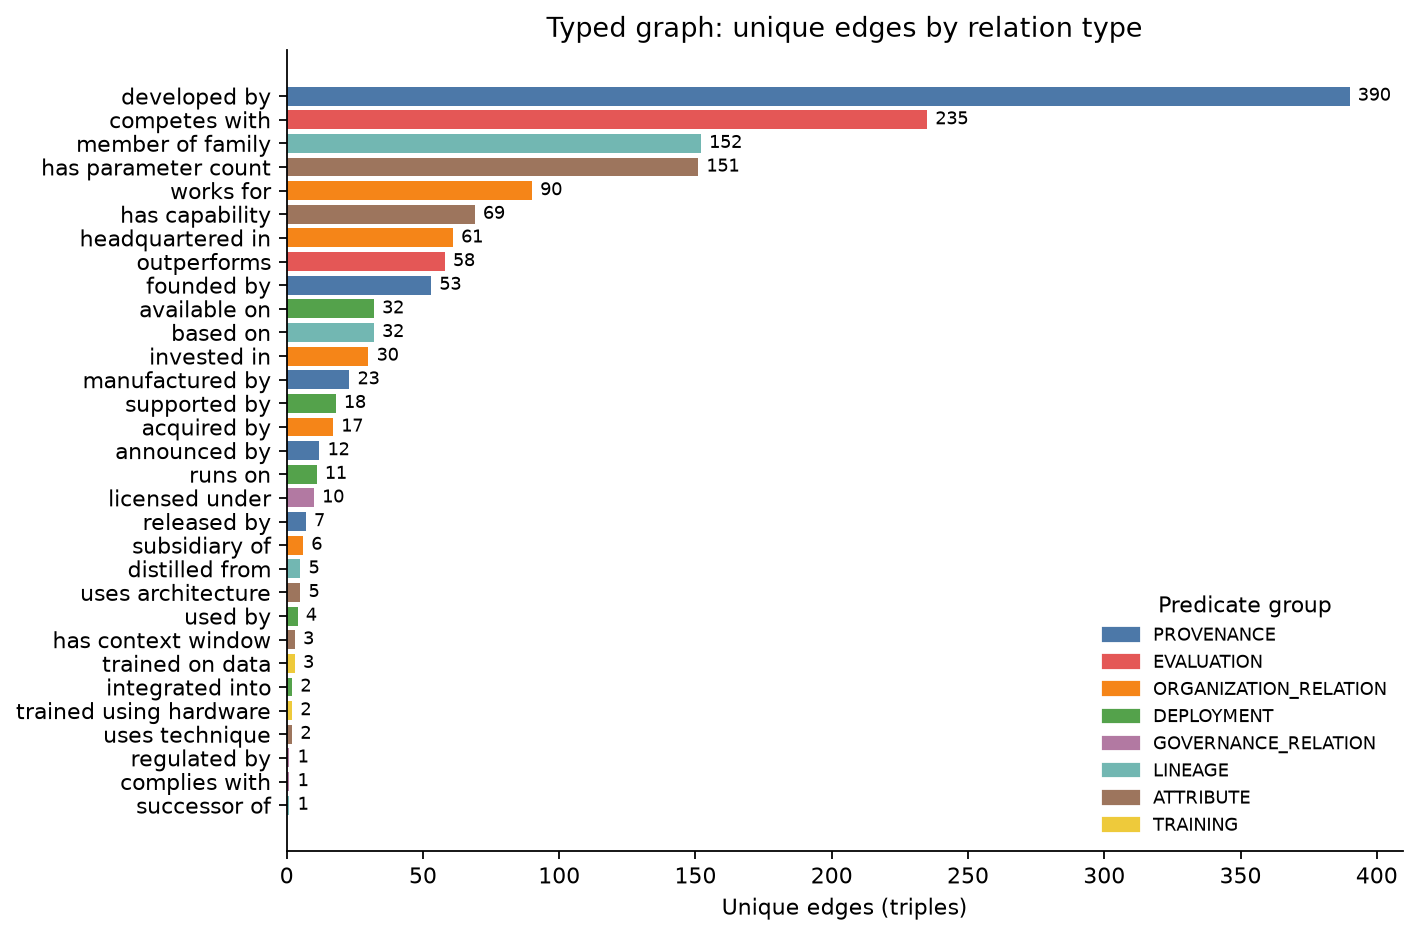

In [11]:
structure = pd.DataFrame(
    {name: graph_summary(graph) for name, graph in
     [("assertion", assertion_graph), ("typed", typed_graph), ("co-occurrence", cooccurrence_graph)]}
).T
ANALYSIS_EXCLUDED_GROUPS = {"ATTRIBUTE"}
analysis_excluded = collapsed["predicate_group"].isin(ANALYSIS_EXCLUDED_GROUPS) | collapsed["added_by"].eq("rule_family_member")
collapsed_analysis = collapsed[~analysis_excluded].copy()
excluded_edges = set(zip(collapsed.loc[analysis_excluded, "subject_id"], collapsed.loc[analysis_excluded, "object_id"],
                         collapsed.loc[analysis_excluded, "predicate"]))
typed_analysis_graph = typed_graph.copy()
typed_analysis_graph.remove_edges_from([edge for edge in typed_graph.edges(keys=True) if edge in excluded_edges])
typed_analysis_graph.remove_nodes_from(list(nx.isolates(typed_analysis_graph)))
structure.loc["typed (분석용: 속성 제외)"] = pd.Series(graph_summary(typed_analysis_graph))
typed_undirected = nx.Graph(typed_analysis_graph.to_undirected())
largest_component = max(nx.connected_components(typed_undirected), key=len)
structure.loc["typed (분석용: 속성 제외)", "largest_component_nodes"] = len(largest_component)
cooc_largest = max(nx.connected_components(cooccurrence_graph), key=len)
structure.loc["co-occurrence", "largest_component_nodes"] = len(cooc_largest)
display(structure)

relation_summary = build_relation_type_summary(collapsed)
relation_summary.insert(1, "predicate_group", relation_summary["predicate"].map(PREDICATE_GROUP))
display(relation_summary)

GROUP_COLORS = {
    "PROVENANCE": "#4C78A8", "EVALUATION": "#E45756", "ORGANIZATION_RELATION": "#F58518",
    "DEPLOYMENT": "#54A24B", "GOVERNANCE_RELATION": "#B279A2", "LINEAGE": "#72B7B2",
    "ATTRIBUTE": "#9D755D", "TRAINING": "#EECA3B",
}
COMPACT_COLORS = {
    "MODEL": "#4C78A8", "ORGANIZATION": "#F58518", "PERSON": "#9D755D", "INFRASTRUCTURE": "#72B7B2",
    "TECHNICAL_COMPONENT": "#54A24B", "MODEL_ATTRIBUTE": "#B279A2", "EVALUATION_RESOURCE": "#EECA3B",
    "GOVERNANCE": "#E45756", "LOCATION_OR_GROUP": "#BAB0AC",
}
plot_data = relation_summary.sort_values("unique_edges")
fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(plot_data["predicate"], plot_data["unique_edges"],
        color=plot_data["predicate_group"].map(GROUP_COLORS))
for y, value in enumerate(plot_data["unique_edges"]):
    ax.text(value + 3, y, str(value), va="center", fontsize=8)
ax.legend(handles=[Patch(color=c, label=g) for g, c in GROUP_COLORS.items() if g in set(plot_data["predicate_group"])],
          title="Predicate group", frameon=False, loc="lower right", fontsize=8)
ax.set(title="Typed graph: unique edges by relation type", xlabel="Unique edges (triples)", ylabel="")
save_figure(fig, "01_relation_type_counts.png")

## 8. Centrality 분석

**왜**: 어떤 entity가 관계망의 중심에 있는지 보기 위해서다. 세 가지 지표를 함께 본다.

- weighted degree: 연결된 relation의 근거 기사 수 합
- PageRank: 중요한 node와 연결될수록 커지는 점수 (edge weight = 근거 기사 수)
- betweenness: 서로 다른 영역을 잇는 다리 역할 (샘플 기반 근사)

typed graph의 PageRank와 betweenness는 방향을 무시한 projection에서 계산한다. 방향이 의미를 가지는
relation은 아래에서 relation별 in/out degree로 따로 해석한다. 예를 들어 `developed by`는 모델 → 조직
방향이므로 조직의 in-degree가 "graph에서 확인된 개발 산출물 수"가 된다.

In [12]:
typed_metrics = calculate_node_metrics(typed_analysis_graph, "typed", "weight", sample_size=1000, seed=SEED)
cooc_metrics = calculate_node_metrics(cooccurrence_graph, "cooccurrence", "document_count", sample_size=500, seed=SEED)
for metrics in (typed_metrics, cooc_metrics):
    metrics["entity_type_compact"] = metrics["entity_id"].map(node_index["entity_type_compact"])

metric_columns = ["canonical_name", "entity_type_compact", "degree", "in_degree", "out_degree",
                  "weighted_degree", "pagerank", "betweenness"]
print("Typed graph - PageRank 상위 15")
display(typed_metrics.head(15)[metric_columns].round(4))
print("Co-occurrence graph - PageRank 상위 15")
display(cooc_metrics.head(15)[[c for c in metric_columns if c in cooc_metrics]].round(4))

relation_metrics = calculate_relation_type_metrics(nodes_kg, collapsed_analysis, sample_size=300, seed=SEED)
relation_views = {
    "developed by": ("in_degree", "개발 산출물이 가장 많이 연결된 조직"),
    "competes with": ("degree", "경쟁 관계가 가장 많은 entity"),
    "works for": ("in_degree", "소속 인물이 가장 많이 연결된 조직"),
    "outperforms": ("out_degree", "다른 모델보다 낫다고 서술된 횟수가 많은 모델"),
}
for predicate, (column, description) in relation_views.items():
    view = relation_metrics[relation_metrics["predicate"] == predicate]
    print(f"[{predicate}] {description} ({column} 기준)")
    display(view.sort_values([column, "weighted_degree"], ascending=False)
                .head(8)[["canonical_name", "entity_type", column, "weighted_degree"]])

Typed graph - PageRank 상위 15


,canonical_name,entity_type_compact,degree,in_degree,out_degree,weighted_degree,pagerank,betweenness
0,NVIDIA,ORGANIZATION,156,142,14,601.0,0.0614,0.2477
1,OpenAI,ORGANIZATION,97,82,15,860.0,0.0530,0.3014
2,Google,ORGANIZATION,110,94,16,654.0,0.0463,0.2080
3,DeepSeek,ORGANIZATION,89,44,45,691.0,0.0420,0.2914
4,Meta,ORGANIZATION,57,43,14,427.0,0.0272,0.0653
5,Anthropic,ORGANIZATION,59,40,19,378.0,0.0245,0.0610
6,Microsoft,ORGANIZATION,50,34,16,255.0,0.0184,0.0604
7,Llama,MODEL,32,15,17,208.0,0.0120,0.0044
8,Nemotron,MODEL,12,2,10,105.0,0.0093,0.0165
9,Amazon,ORGANIZATION,28,14,14,132.0,0.0092,0.0253


Co-occurrence graph - PageRank 상위 15


,canonical_name,entity_type_compact,degree,weighted_degree,pagerank,betweenness
0,NVIDIA,ORGANIZATION,1099,11402.0,0.0319,0.3095
1,DeepSeek,ORGANIZATION,905,12343.0,0.0311,0.1785
2,OpenAI,ORGANIZATION,729,12815.0,0.0303,0.2909
3,Google,ORGANIZATION,802,10917.0,0.0279,0.2157
4,united_states,LOCATION_OR_GROUP,632,9174.0,0.0219,0.1068
5,open_source_model,MODEL_ATTRIBUTE,543,9129.0,0.0214,0.1213
6,Llama,MODEL,611,8206.0,0.0206,0.0947
7,China,LOCATION_OR_GROUP,501,7044.0,0.0166,0.0428
8,Meta,ORGANIZATION,438,6852.0,0.0157,0.0379
9,Anthropic,ORGANIZATION,419,6936.0,0.0155,0.0256


[developed by] 개발 산출물이 가장 많이 연결된 조직 (in_degree 기준)


...

,canonical_name,entity_type,degree,weighted_degree
115,Google,COMPANY,33,372.0
114,OpenAI,COMPANY,28,458.0
116,DeepSeek,COMPANY,28,330.0
117,Anthropic,COMPANY,26,261.0
119,NVIDIA,COMPANY,20,111.0
118,Meta,COMPANY,19,213.0
120,Microsoft,COMPANY,16,142.0
121,Alibaba,COMPANY,15,99.0


[works for] 소속 인물이 가장 많이 연결된 조직 (in_degree 기준)


,canonical_name,entity_type,in_degree,weighted_degree
1003,NVIDIA,COMPANY,10,26.0
1004,Meta,COMPANY,6,29.0
1005,Microsoft,COMPANY,6,14.0
1006,Google,COMPANY,6,9.0
1010,OpenAI,COMPANY,3,12.0
1008,Anthropic,COMPANY,3,6.0
1007,IBM,COMPANY,3,5.0
1009,Red Hat,COMPANY,3,3.0


[outperforms] 다른 모델보다 낫다고 서술된 횟수가 많은 모델 (out_degree 기준)


,canonical_name,entity_type,out_degree,weighted_degree
881,DeepSeek,COMPANY,9,74.0
883,Qwen,FOUNDATION_MODEL,6,38.0
884,GPT-4o,AI_MODEL,6,27.0
885,Kimi,FOUNDATION_MODEL,5,20.0
889,GLM,FOUNDATION_MODEL,4,11.0
887,Mistral,FOUNDATION_MODEL,3,14.0
895,Phi,FOUNDATION_MODEL,3,9.0
882,Llama,FOUNDATION_MODEL,2,38.0


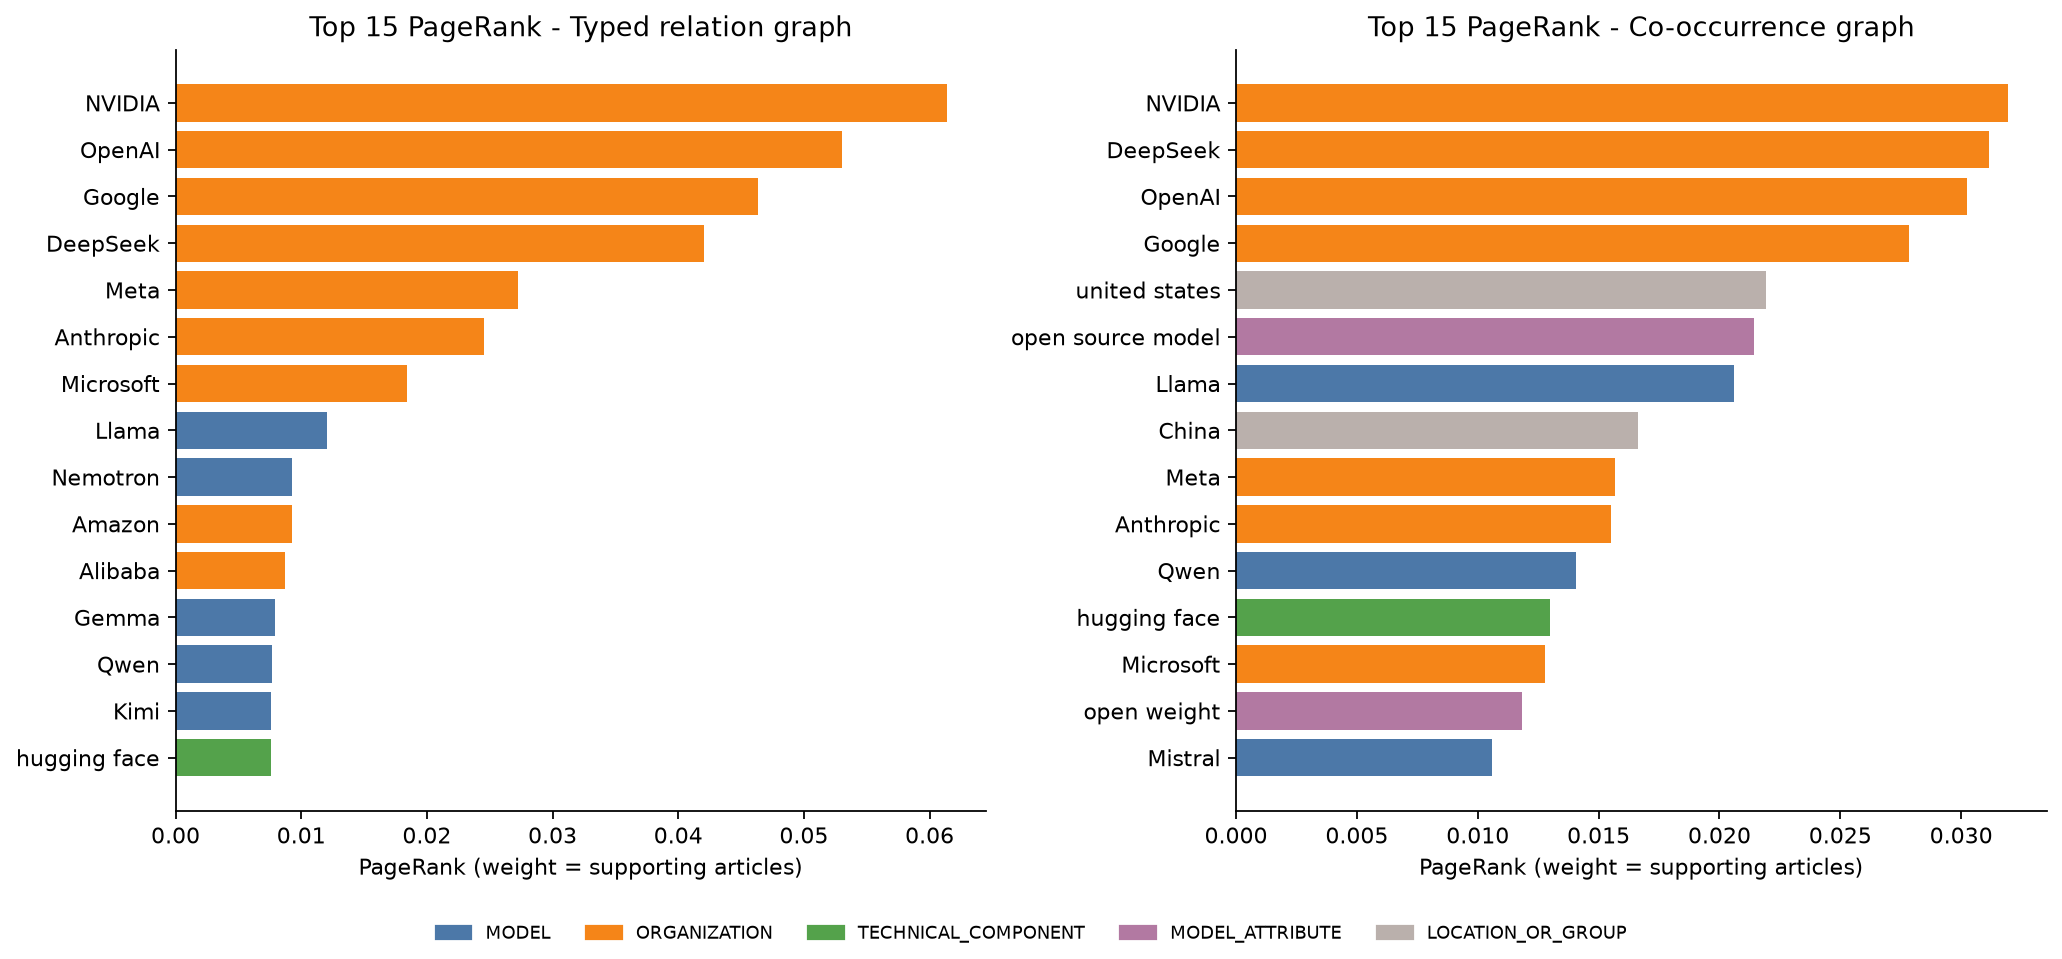

두 view의 PageRank 상위 20 중 겹치는 entity: 14개 -> Anthropic, China, DeepSeek, Gemini, Gemma, Google, Llama, Meta, Microsoft, Mistral, NVIDIA, OpenAI, Qwen, hugging_face


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, metrics, title in [(axes[0], typed_metrics, "Typed relation graph"),
                           (axes[1], cooc_metrics, "Co-occurrence graph")]:
    top = metrics.head(15).iloc[::-1]
    ax.barh(top["canonical_name"].map(pretty), top["pagerank"], color=top["entity_type_compact"].map(COMPACT_COLORS))
    ax.set(title=f"Top 15 PageRank - {title}", xlabel="PageRank (weight = supporting articles)")
present = set(typed_metrics.head(15)["entity_type_compact"]) | set(cooc_metrics.head(15)["entity_type_compact"])
fig.legend(handles=[Patch(color=COMPACT_COLORS[t], label=t) for t in COMPACT_COLORS if t in present],
           loc="lower center", ncol=len(present), frameon=False, fontsize=8)
fig.tight_layout(rect=(0, 0.05, 1, 1))
save_figure(fig, "02_pagerank_typed_vs_cooccurrence.png")

overlap = set(typed_metrics.head(20)["entity_id"]) & set(cooc_metrics.head(20)["entity_id"])
print(f"두 view의 PageRank 상위 20 중 겹치는 entity: {len(overlap)}개 -> "
      + ", ".join(sorted(node_index.loc[list(overlap), "canonical_name"])))

In [14]:
labels = node_index["canonical_name"]
top7 = typed_metrics.head(7)
dev = relation_metrics[relation_metrics["predicate"] == "developed by"].nlargest(1, "in_degree").iloc[0]
dev_products = collapsed[(collapsed["predicate"] == "developed by") & (collapsed["object_id"] == dev["entity_id"])]
comp = relation_metrics[relation_metrics["predicate"] == "competes with"].nlargest(1, "weighted_degree").iloc[0]
bridge = typed_metrics.nlargest(1, "betweenness").iloc[0]
context = cooc_metrics.head(15)
context = context[context["entity_type_compact"].isin(["LOCATION_OR_GROUP", "MODEL_ATTRIBUTE"])]["canonical_name"].map(pretty)
if comp["entity_id"] == bridge["entity_id"]:
    comp_text = (f"{comp['canonical_name']}은 `competes with` weighted degree({int(comp['weighted_degree'])})와 "
                 f"betweenness({bridge['betweenness']:.2f})가 모두 가장 커서 여러 조직·모델을 잇는 위치에 있다.")
else:
    comp_text = (f"`competes with` weighted degree는 {comp['canonical_name']}({int(comp['weighted_degree'])})가, betweenness는 "
                 f"{bridge['canonical_name']}({bridge['betweenness']:.2f})가 가장 크다.")
display(Markdown(f'''
**해석 (검토 전 초안)**

- typed graph의 PageRank 상위 7개는 {", ".join(top7["canonical_name"])}이다
  ({", ".join(sorted(set(top7["entity_type_compact"])))}). 상위 15위 안의 모델 family:
  {", ".join(typed_metrics.head(15).query("entity_type_compact == 'MODEL'")["canonical_name"])}.
- `developed by` in-degree가 가장 큰 조직은 **{dev["canonical_name"]}**({int(dev["in_degree"])}개 산출물; 예:
  {", ".join(dev_products.nlargest(4, "document_count")["subject_id"].map(labels))})이다. 하드웨어 공급자이면서 모델·소프트웨어
  개발사로 가장 많은 산출물과 연결되어 있다.
- {comp_text}
- co-occurrence graph에서는 {", ".join(context)}처럼 맥락을 나타내는 entity가 상위에 들어온다. 같은 문장에 함께
  쓰인 빈도라서 담론의 배경(미·중 경쟁, open vs closed 논쟁)을 반영한다.
- 두 view의 PageRank 상위 20 중 {len(overlap)}개가 겹쳐 **핵심 행위자 집합**은 view에 덜 민감하다. 그러나 보정 전 graph의
  민감도 분석에서 **순위**는 score threshold에 따라 크게 바뀌었으므로 산업 영향력 순위로 표현하지 않는다.
'''))


**해석 (검토 전 초안)**

- typed graph의 PageRank 상위 7개는 NVIDIA, OpenAI, Google, DeepSeek, Meta, Anthropic, Microsoft이다
  (ORGANIZATION). 상위 15위 안의 모델 family:
  Llama, Nemotron, Gemma, Qwen, Kimi.
- `developed by` in-degree가 가장 큰 조직은 **NVIDIA**(80개 산출물; 예:
  Nemotron, DGX Spark, NemoClaw, Blackwell architecture)이다. 하드웨어 공급자이면서 모델·소프트웨어
  개발사로 가장 많은 산출물과 연결되어 있다.
- OpenAI은 `competes with` weighted degree(458)와 betweenness(0.30)가 모두 가장 커서 여러 조직·모델을 잇는 위치에 있다.
- co-occurrence graph에서는 united states, open source model, China, open weight처럼 맥락을 나타내는 entity가 상위에 들어온다. 같은 문장에 함께
  쓰인 빈도라서 담론의 배경(미·중 경쟁, open vs closed 논쟁)을 반영한다.
- 두 view의 PageRank 상위 20 중 14개가 겹쳐 **핵심 행위자 집합**은 view에 덜 민감하다. 그러나 보정 전 graph의
  민감도 분석에서 **순위**는 score threshold에 따라 크게 바뀌었으므로 산업 영향력 순위로 표현하지 않는다.


## 9. Clustering과 community

**왜**: 함께 언급되는 entity 묶음은 담론의 하위 주제(예: 중국 오픈 모델, NVIDIA 하드웨어 생태계)를
보여 준다. clustering coefficient는 triangle이 많은 co-occurrence graph에서 의미가 있고, 희소한 typed
graph에서는 낮게 나오는 것이 정상이다. community는 문서 수를 weight로 한 greedy modularity로 찾는다.

In [15]:
clustering_table = pd.DataFrame(
    [
        ("typed (undirected projection)", nx.average_clustering(typed_undirected), np.nan,
         nx.transitivity(typed_undirected)),
        ("co-occurrence", nx.average_clustering(cooccurrence_graph),
         nx.average_clustering(cooccurrence_graph, weight="document_count"), nx.transitivity(cooccurrence_graph)),
    ],
    columns=["view", "average clustering", "weighted average clustering", "transitivity"],
).round(4)
display(clustering_table)

community_members, community_summary = detect_cooccurrence_communities(cooccurrence_graph)
community_sets = [set(group["entity_id"]) for _, group in community_members.groupby("community_id")]
modularity = nx.community.modularity(cooccurrence_graph, community_sets, weight="document_count")
community_summary["top_entities"] = community_summary["top_entities"].map(lambda v: ", ".join(json.loads(v)[:8]))
community_summary["share_of_nodes"] = (community_summary["node_count"] / cooccurrence_graph.number_of_nodes()).round(3)
print(f"community {len(community_summary)}개 | modularity {modularity:.3f}")
display(community_summary.head(10))

,view,average clustering,weighted average clustering,transitivity
0,typed (undirected projection),0.0939,NaN,0.0679
1,co-occurrence,0.5409,0.008,0.0776


community 192개 | modularity 0.236


,community_id,node_count,edge_count,top_entities,share_of_nodes
0,1,1666,6739,"OpenAI, Google, open_source_model, Llama, Anth...",0.343
1,2,1338,3899,"united_states, DeepSeek, China, NVIDIA, Micros...",0.275
2,3,896,3582,"vllm, Nemotron, Google Cloud, IBM, Dell Techno...",0.184
3,4,124,313,"TrueFoundry, observability, routing, reliabili...",0.026
4,5,97,162,"MLA, Grouped-Query Attention, Multi-Head Atten...",0.020
5,6,44,65,"Facebook, Instagram, WhatsApp, Discord, Messen...",0.009
6,7,29,36,"MLLM, ControlNet, CLIP, T5-XXL, SD3, IP-Adapte...",0.006
7,8,16,32,"Kit, WebGPU, personality, Nico, Michael Knight...",0.003
8,9,16,49,"Arka Venture Labs, Astir VC, Good News Venture...",0.003
9,10,15,27,"Liquid AI, LFMs, Liquid, liquid neural network...",0.003


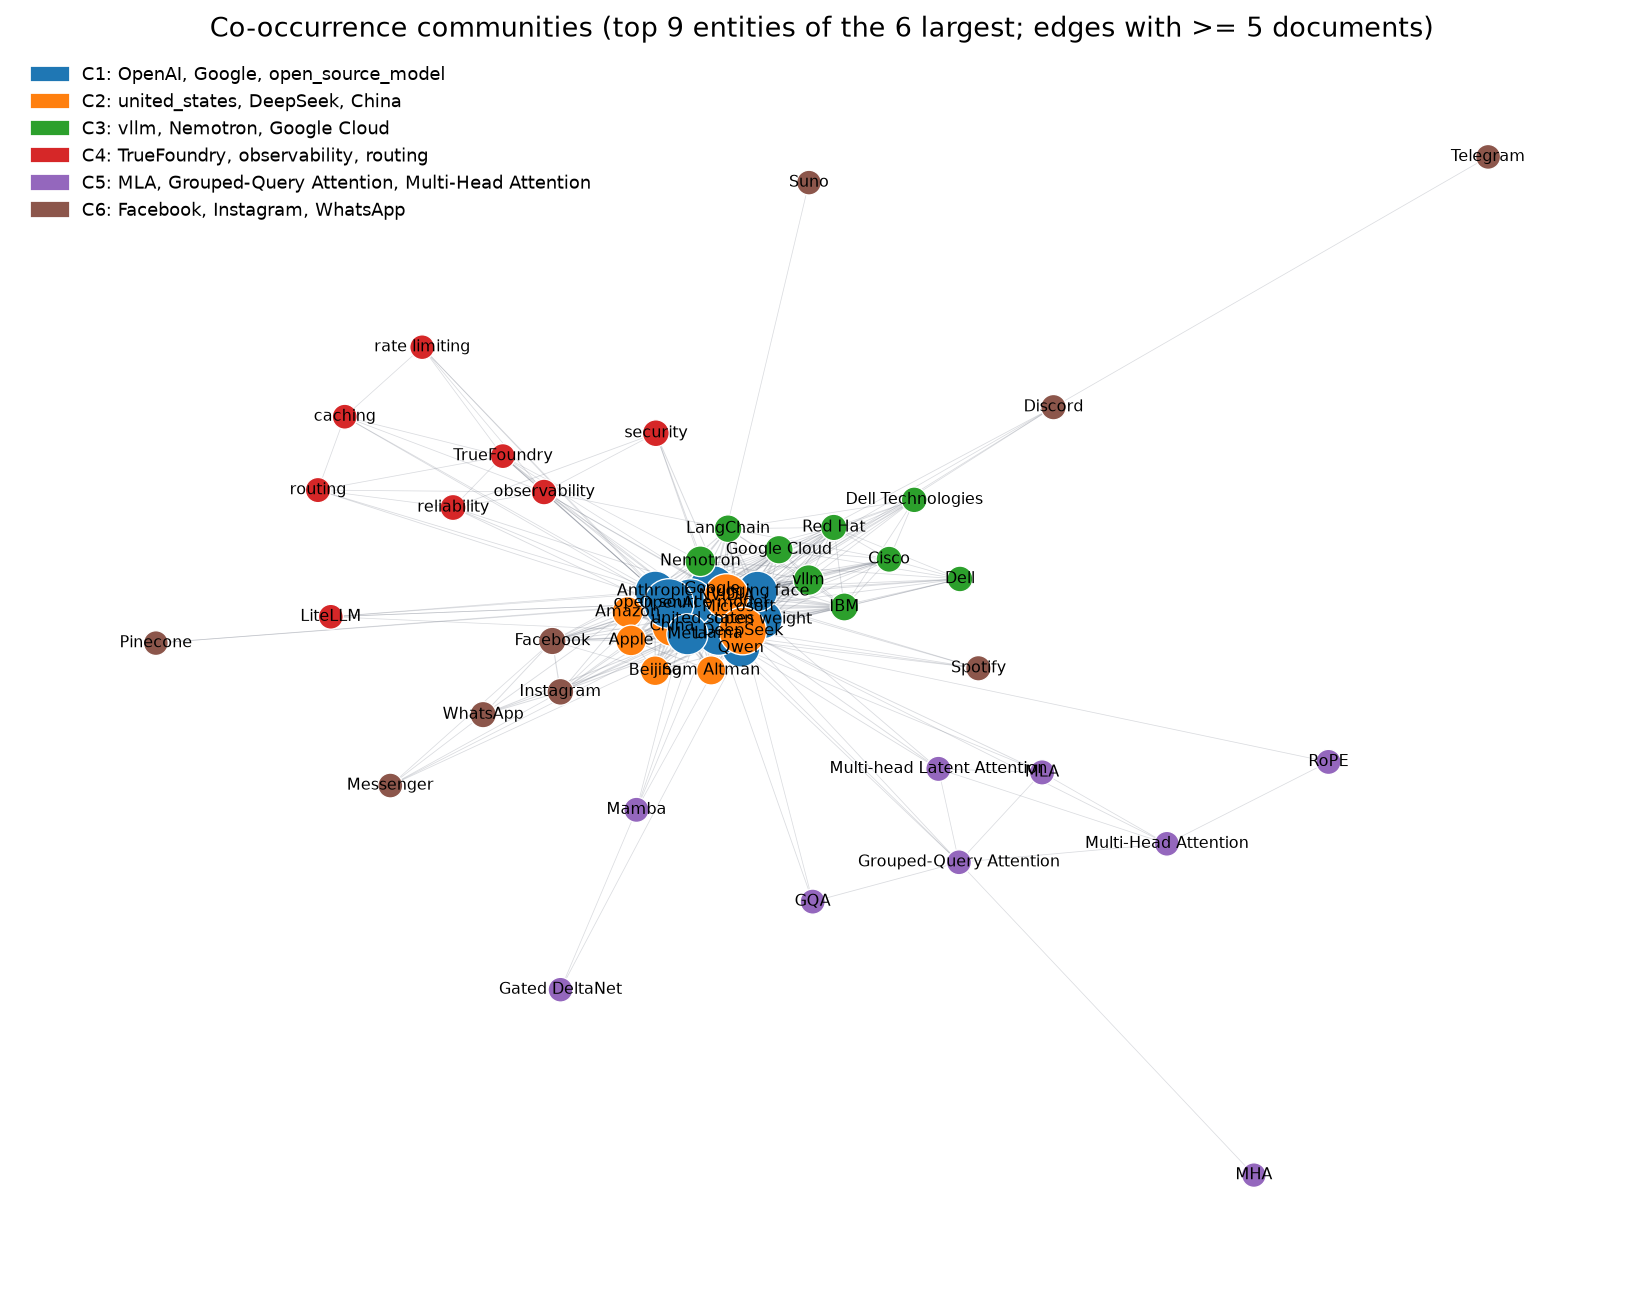

In [16]:
TOP_COMMUNITIES = 6
NODES_PER_COMMUNITY = 9
top_members = community_members[
    (community_members["community_id"] <= TOP_COMMUNITIES)
    & (community_members["rank_in_community"] <= NODES_PER_COMMUNITY)
]
draw = cooccurrence_graph.subgraph(top_members["entity_id"]).copy()
draw.remove_edges_from([(a, b) for a, b, d in draw.edges(data=True)
                        if d["document_count"] < DRAW_COOCCURRENCE_DOCUMENTS])
draw.remove_nodes_from(list(nx.isolates(draw)))
community_of = top_members.set_index("entity_id")["community_id"]
palette = plt.get_cmap("tab10")
positions = nx.spring_layout(draw, seed=SEED, weight="document_count", k=2.4 / np.sqrt(max(len(draw), 1)), iterations=500)
fig, ax = plt.subplots(figsize=(13, 10))
widths = [0.3 + 2.5 * d["document_count"] / max(nx.get_edge_attributes(draw, "document_count").values())
          for _, _, d in draw.edges(data=True)]
nx.draw_networkx_edges(draw, positions, width=widths, alpha=0.25, edge_color="#6B7280", ax=ax)
nx.draw_networkx_nodes(draw, positions, ax=ax, linewidths=0.6, edgecolors="white",
                       node_color=[palette(community_of[n] - 1) for n in draw],
                       node_size=[120 + 0.6 * draw.nodes[n]["document_count"] for n in draw])
nx.draw_networkx_labels(draw, positions, labels={n: pretty(draw.nodes[n]["label"]) for n in draw}, font_size=7, ax=ax)
legend_labels = community_summary.set_index("community_id")["top_entities"]
ax.legend(handles=[Patch(color=palette(c - 1), label=f"C{c}: " + ", ".join(legend_labels[c].split(", ")[:3]))
                   for c in range(1, TOP_COMMUNITIES + 1)], loc="upper left", frameon=False, fontsize=8)
ax.set_title(f"Co-occurrence communities (top {NODES_PER_COMMUNITY} entities of the {TOP_COMMUNITIES} largest; "
             f"edges with >= {DRAW_COOCCURRENCE_DOCUMENTS} documents)")
ax.axis("off")
save_figure(fig, "03_cooccurrence_communities.png")

In [17]:
c = community_summary.set_index("community_id").assign(top_entities=lambda d: d["top_entities"].map(pretty))
display(Markdown(f'''
**해석 (검토 전 초안)**

- 평균 clustering은 co-occurrence graph가 {clustering_table.loc[1, "average clustering"]:.2f}, typed graph가
  {clustering_table.loc[0, "average clustering"]:.2f}이다. 공동출현은 한 기사 안의 여러 entity가 서로 묶여 triangle이 많고,
  typed graph는 모델 → 개발사처럼 별 모양 구조라 낮게 나오는 것이 정상이다.
- greedy modularity로 {len(community_summary)}개 community를 찾았고 modularity는 {modularity:.3f}이다. 값이 낮은 것은 주요
  조직·모델이 대부분의 기사에서 함께 언급되어 경계가 뚜렷하지 않기 때문이다.
- 그래도 상위 3개 community(전체 node의 {c.loc[[1, 2, 3], "share_of_nodes"].sum():.0%})는 해석 가능한 담론 묶음으로 보인다.
  - **C1 ({c.loc[1, "share_of_nodes"]:.0%})** {c.loc[1, "top_entities"]}: 미국 frontier lab과 open vs closed 모델 논의
  - **C2 ({c.loc[2, "share_of_nodes"]:.0%})** {c.loc[2, "top_entities"]}: DeepSeek 이후 미·중 경쟁, 칩, 수출 통제 담론
  - **C3 ({c.loc[3, "share_of_nodes"]:.0%})** {c.loc[3, "top_entities"]}: 기업용 배포·추론 인프라
  - 작은 community는 특정 기사 주제다. 예: {c.loc[4, "top_entities"].split(", ")[0]}({c.loc[4, "node_count"]}개 node),
    {c.loc[5, "top_entities"].split(", ")[0]}({c.loc[5, "node_count"]}개 node)
- community 이름은 상위 entity를 보고 붙인 해석이므로 검토 대상이다.
'''))


**해석 (검토 전 초안)**

- 평균 clustering은 co-occurrence graph가 0.54, typed graph가
  0.09이다. 공동출현은 한 기사 안의 여러 entity가 서로 묶여 triangle이 많고,
  typed graph는 모델 → 개발사처럼 별 모양 구조라 낮게 나오는 것이 정상이다.
- greedy modularity로 192개 community를 찾았고 modularity는 0.236이다. 값이 낮은 것은 주요
  조직·모델이 대부분의 기사에서 함께 언급되어 경계가 뚜렷하지 않기 때문이다.
- 그래도 상위 3개 community(전체 node의 80%)는 해석 가능한 담론 묶음으로 보인다.
  - **C1 (34%)** OpenAI, Google, open source model, Llama, Anthropic, Qwen, Meta, open weight: 미국 frontier lab과 open vs closed 모델 논의
  - **C2 (28%)** united states, DeepSeek, China, NVIDIA, Microsoft, Beijing, Apple, Sam Altman: DeepSeek 이후 미·중 경쟁, 칩, 수출 통제 담론
  - **C3 (18%)** vllm, Nemotron, Google Cloud, IBM, Dell Technologies, Cisco, Red Hat, LangChain: 기업용 배포·추론 인프라
  - 작은 community는 특정 기사 주제다. 예: TrueFoundry(124개 node),
    MLA(97개 node)
- community 이름은 상위 entity를 보고 붙인 해석이므로 검토 대상이다.


## 10. 시간 분석

모든 날짜는 기사 발행일이므로 "그 시점에 데이터셋에서 관찰된 관계"로 해석한다.

1. 분기별 relation 근거 문장 수 (predicate group별)
2. 분기별 새로 처음 관찰된 typed triple 수
3. 주요 open model family의 분기별 언급 기사 비율 (WP2 `nodes_quarterly`)
4. 2026년에 처음 관찰된 relation (emerging relationship 후보)
5. 전반기(P1)와 후반기(P2) 사이 relation 근거 비중이 가장 크게 늘어난 entity

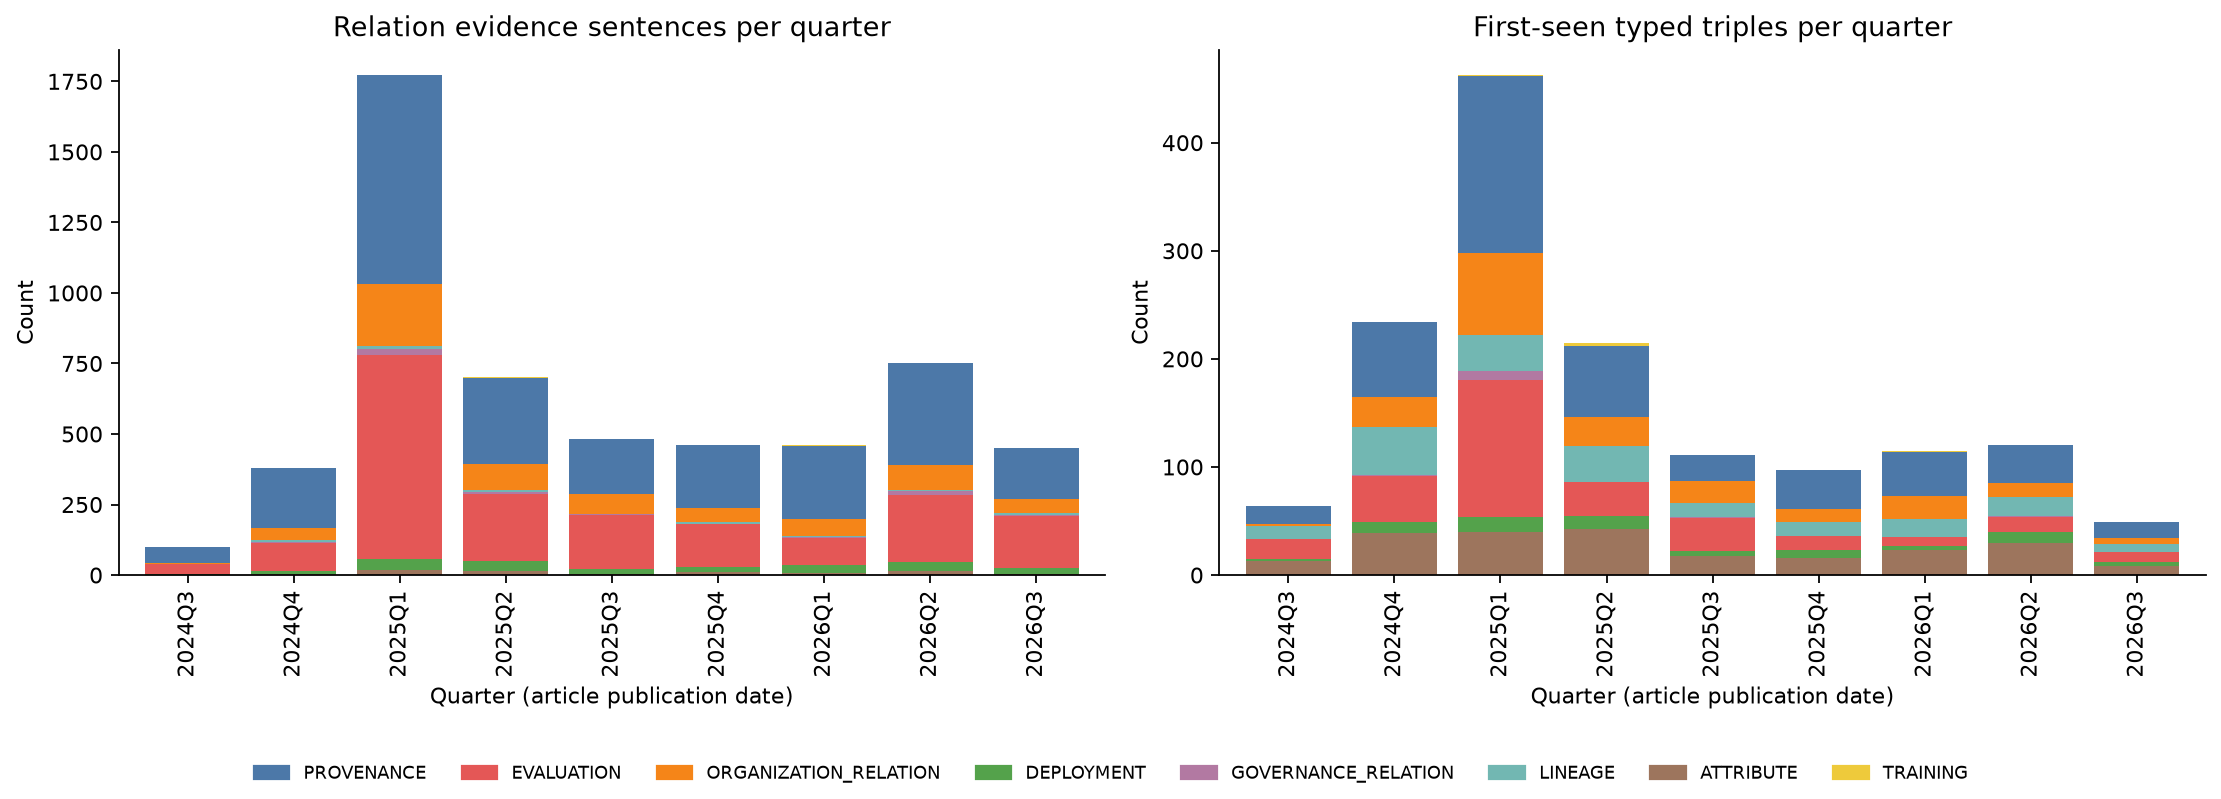

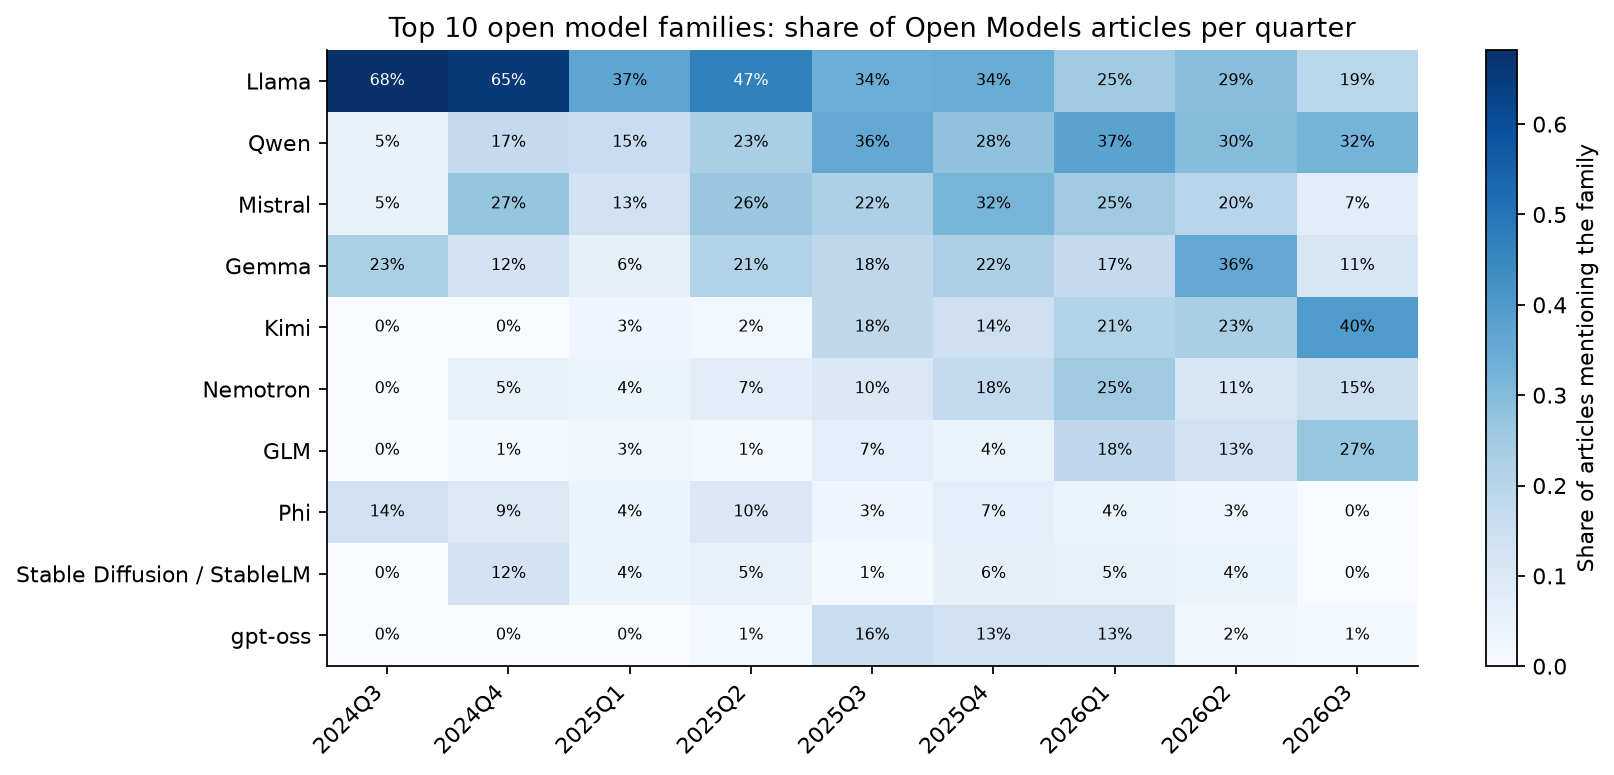

quarter,2024Q3,2024Q4,2025Q1,2025Q2,2025Q3,2025Q4,2026Q1,2026Q2,2026Q3
기사 수,22,104,349,156,103,90,99,179,108


In [18]:
dated = assertions[assertions["extraction_method"] == "glirel"].copy()
dated["quarter"] = pd.to_datetime(dated["published_at"]).dt.to_period("Q").astype(str)
dated["predicate_group"] = dated["predicate"].map(PREDICATE_GROUP)
quarterly_assertions = dated.pivot_table(index="quarter", columns="predicate_group", values="relation_id",
                                         aggfunc="count", fill_value=0)

new_edges = collapsed[collapsed["first_seen"].notna()].copy()
new_edges["quarter"] = pd.to_datetime(new_edges["first_seen"]).dt.to_period("Q").astype(str)
quarterly_new_edges = new_edges.pivot_table(index="quarter", columns="predicate_group", values="predicate",
                                            aggfunc="count", fill_value=0)

mentions = pd.read_csv(WP2_INPUT_DIR / "entity_mentions.csv", usecols=["doc_id", "quarter"])
documents_per_quarter = mentions.drop_duplicates("doc_id")["quarter"].value_counts().sort_index()
families = nodes_kg[nodes_kg["is_open_model_family"]].set_index("entity_id")["canonical_name"]
family_quarterly = nodes_quarterly.assign(entity_id=nodes_quarterly["entity_id"].map(id_map))
family_quarterly = (family_quarterly[family_quarterly["entity_id"].isin(families.index)]
                    .groupby(["entity_id", "quarter"])["n_docs"].sum().unstack(fill_value=0))
family_share = family_quarterly.div(documents_per_quarter.reindex(family_quarterly.columns), axis=1)
top_families = family_quarterly.sum(axis=1).nlargest(10).index
family_share = family_share.loc[top_families].rename(index=families)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, table, title in [(axes[0], quarterly_assertions, "Relation evidence sentences per quarter"),
                         (axes[1], quarterly_new_edges, "First-seen typed triples per quarter")]:
    table.plot(ax=ax, kind="bar", stacked=True, width=0.8,
               color=[GROUP_COLORS.get(c, "#BAB0AC") for c in table.columns], legend=False)
    ax.set(title=title, xlabel="Quarter (article publication date)", ylabel="Count")
handles = [Patch(color=GROUP_COLORS[g], label=g) for g in GROUP_COLORS if g in set(quarterly_assertions.columns)]
fig.legend(handles=handles, loc="lower center", ncol=len(handles), frameon=False, fontsize=8)
fig.tight_layout(rect=(0, 0.07, 1, 1))
save_figure(fig, "04_quarterly_relations.png")

fig, ax = plt.subplots(figsize=(11, 5))
image = ax.imshow(family_share.values, aspect="auto", cmap="Blues")
ax.set_xticks(range(family_share.shape[1]), family_share.columns, rotation=45, ha="right")
ax.set_yticks(range(family_share.shape[0]), family_share.index)
for (i, j), value in np.ndenumerate(family_share.values):
    ax.text(j, i, f"{value:.0%}", ha="center", va="center", fontsize=7,
            color="white" if value > family_share.values.max() * 0.6 else "black")
fig.colorbar(image, ax=ax, label="Share of articles mentioning the family")
ax.set_title("Top 10 open model families: share of Open Models articles per quarter")
save_figure(fig, "05_family_quarterly_share.png")
display(documents_per_quarter.rename("기사 수").to_frame().T)

In [19]:
labels = node_index["canonical_name"]
emerging = collapsed_analysis[(collapsed_analysis["first_seen"].fillna("") >= "2026-01-01")
                              & (collapsed_analysis["document_count"] >= 2)].copy()
emerging["edge"] = emerging["subject_id"].map(labels) + " -> " + emerging["predicate"] + " -> " + emerging["object_id"].map(labels)
print(f"2026년에 처음 관찰되고 2개 이상 기사로 뒷받침되는 triple: {len(emerging)}개")
display(emerging.sort_values(["document_count", "first_seen"], ascending=[False, True])
        .head(15)[["edge", "predicate_group", "document_count", "first_seen", "last_seen"]])

dated_analysis = dated[~dated["predicate_group"].isin(ANALYSIS_EXCLUDED_GROUPS)]

def period_share(start, end):
    rows = dated_analysis[(dated_analysis["published_at"] >= start) & (dated_analysis["published_at"] <= end)]
    long = pd.concat([rows[["subject_id", "document_id"]].rename(columns={"subject_id": "entity_id"}),
                      rows[["object_id", "document_id"]].rename(columns={"object_id": "entity_id"})])
    per_entity = long.drop_duplicates().groupby("entity_id")["document_id"].nunique()
    return per_entity / rows["document_id"].nunique()

shares = pd.DataFrame({name: period_share(*span) for name, span in PERIODS.items()}).fillna(0)
p1, p2 = shares.columns
shares["change_pp"] = (shares[p2] - shares[p1]) * 100
shares["canonical_name"] = shares.index.map(labels)
shares["entity_type_compact"] = shares.index.map(node_index["entity_type_compact"])
print("relation 근거 기사 비중 변화 (P2 - P1, %p)")
display(pd.concat([shares.nlargest(10, "change_pp"), shares.nsmallest(5, "change_pp")])
        [["canonical_name", "entity_type_compact", p1, p2, "change_pp"]].round(3))

2026년에 처음 관찰되고 2개 이상 기사로 뒷받침되는 triple: 122개


,edge,predicate_group,document_count,first_seen,last_seen
652,NemoClaw -> developed by -> NVIDIA,PROVENANCE,9,2026-03-11,2026-08-11
14,Latent Space -> acquired by -> AINews,ORGANIZATION_RELATION,8,2026-03-25,2026-05-28
477,Muse Spark -> developed by -> Meta,PROVENANCE,7,2026-04-08,2026-07-24
114,GLM -> competes with -> Anthropic,EVALUATION,5,2026-06-25,2026-08-19
585,AI Gateway -> developed by -> TrueFoundry,PROVENANCE,4,2026-03-02,2026-06-04
571,OpenClaw -> developed by -> NVIDIA,PROVENANCE,4,2026-03-11,2026-04-30
573,OpenShell -> developed by -> NVIDIA,PROVENANCE,4,2026-03-16,2026-07-27
481,Mythos -> developed by -> Anthropic,PROVENANCE,4,2026-04-04,2026-06-12
1454,Michael Kratsios -> works for -> White House,ORGANIZATION_RELATION,4,2026-04-23,2026-07-31
440,GPT-5.5 -> developed by -> OpenAI,PROVENANCE,4,2026-04-24,2026-06-23


relation 근거 기사 비중 변화 (P2 - P1, %p)


,canonical_name,entity_type_compact,P1 (2024-09~2025-08),P2 (2025-09~2026-08),change_pp
entity_id,,,,,
org:anthropic,Anthropic,ORGANIZATION,0.141,0.286,14.480
model:nemotron,Nemotron,MODEL,0.043,0.142,9.821
model:kimi,Kimi,MODEL,0.027,0.109,8.182
org:nvidia,NVIDIA,ORGANIZATION,0.212,0.272,6.052
model:gemma,Gemma,MODEL,0.074,0.125,5.107
model:glm,GLM,MODEL,0.007,0.057,4.997
org:moonshot_ai,MoonShot AI,ORGANIZATION,0.014,0.060,4.545
org:google,Google,ORGANIZATION,0.315,0.351,3.628
person:jensen_huang,Jensen Huang,PERSON,0.022,0.049,2.731


In [20]:
peak_quarter = documents_per_quarter.idxmax()
fs = family_share
first_q = next(q for q in fs.columns if documents_per_quarter[q] >= 50)  # 기사 수가 너무 적은 첫 분기는 기준에서 제외
last_q = fs.columns[-1]
quarter_totals = quarterly_assertions.sum(axis=1)
risers, fallers = shares.nlargest(5, "change_pp"), shares.nsmallest(3, "change_pp")
emerging_groups = emerging["predicate_group"].value_counts()
display(Markdown(f'''
**해석 (검토 전 초안)**

- **{peak_quarter} 집중**: 기사 {documents_per_quarter[peak_quarter]}개, relation 근거 문장 {quarter_totals[peak_quarter]:,}개로 가장 많다
  (분기 중앙값 {int(quarter_totals.median()):,}개, DeepSeek-R1 공개 직후). 따라서 분기 비교는 기사 수로 정규화한 지표
  (family 비율, 근거 기사 비중)를 우선한다.
- **family 담론의 이동** ({fs.columns[0]}은 기사 {documents_per_quarter[fs.columns[0]]}개뿐이라 {first_q}를 기준으로 비교):
  Llama를 언급한 기사 비율은 {first_q} {fs.loc["Llama", first_q]:.0%}에서 {last_q} {fs.loc["Llama", last_q]:.0%}로
  낮아졌다. Qwen은 {fs.loc["Qwen", first_q]:.0%} → {fs.loc["Qwen", last_q]:.0%}, Kimi는 {fs.loc["Kimi", first_q]:.0%} → {fs.loc["Kimi", last_q]:.0%},
  GLM은 {fs.loc["GLM", first_q]:.0%} → {fs.loc["GLM", last_q]:.0%}로 올라갔다. Nemotron은 {fs.loc["Nemotron"].idxmax()}에
  {fs.loc["Nemotron"].max():.0%}로 가장 높았다.
- **relation 근거 비중 변화 (P1 → P2)**: {", ".join(f"{r.canonical_name} {r.change_pp:+.1f}%p" for r in risers.itertuples())}가 늘었고,
  {", ".join(f"{r.canonical_name} {r.change_pp:+.1f}%p" for r in fallers.itertuples())}가 줄었다.
- **2026년에 처음 관찰된 relation** (속성 제외): {len(emerging)}개({", ".join(f"{g} {n}" for g, n in emerging_groups.items())}).
  출처(PROVENANCE) 예시는
  {", ".join(emerging[emerging["predicate_group"] == "PROVENANCE"].nlargest(4, "document_count")["edge"])}이다.
  검수 전 relation에는 오류가 남아 있으므로 개별 relation을 사실로 인용하기 전에 근거 문장을 확인한다.
- 2024Q3은 9월, 2026Q3은 7~8월만 포함한다. 날짜는 모두 기사 발행일이다.
'''))


**해석 (검토 전 초안)**

- **2025Q1 집중**: 기사 349개, relation 근거 문장 1,774개로 가장 많다
  (분기 중앙값 461개, DeepSeek-R1 공개 직후). 따라서 분기 비교는 기사 수로 정규화한 지표
  (family 비율, 근거 기사 비중)를 우선한다.
- **family 담론의 이동** (2024Q3은 기사 22개뿐이라 2024Q4를 기준으로 비교):
  Llama를 언급한 기사 비율은 2024Q4 65%에서 2026Q3 19%로
  낮아졌다. Qwen은 17% → 32%, Kimi는 0% → 40%,
  GLM은 1% → 27%로 올라갔다. Nemotron은 2026Q1에
  25%로 가장 높았다.
- **relation 근거 비중 변화 (P1 → P2)**: Anthropic +14.5%p, Nemotron +9.8%p, Kimi +8.2%p, NVIDIA +6.1%p, Gemma +5.1%p가 늘었고,
  DeepSeek -28.1%p, Meta -13.0%p, Llama -11.4%p가 줄었다.
- **2026년에 처음 관찰된 relation** (속성 제외): 122개(PROVENANCE 58, ORGANIZATION_RELATION 25, EVALUATION 24, DEPLOYMENT 14, GOVERNANCE_RELATION 1).
  출처(PROVENANCE) 예시는
  NemoClaw -> developed by -> NVIDIA, Muse Spark -> developed by -> Meta, GPT-5.5 -> developed by -> OpenAI, Mythos -> developed by -> Anthropic이다.
  검수 전 relation에는 오류가 남아 있으므로 개별 relation을 사실로 인용하기 전에 근거 문장을 확인한다.
- 2024Q3은 9월, 2026Q3은 7~8월만 포함한다. 날짜는 모두 기사 발행일이다.


## 11. 목적별 graph 시각화

전체 graph를 한 그림에 그리면 읽을 수 없으므로 질문별로 subgraph를 나눈다. 모든 그림에서 node 색은
compact entity type, edge 색은 predicate group이고, threshold는 제목에 적었다.

1. **핵심 typed graph**: typed PageRank 상위 entity 사이의 relation
2. **Open model family → developer**: lexicon(Tier A)과 기사 근거(Tier B)를 선 모양으로 구분
3. **경쟁·성능 비교**: `competes with`(점선, 방향 없음)와 `outperforms`(화살표)

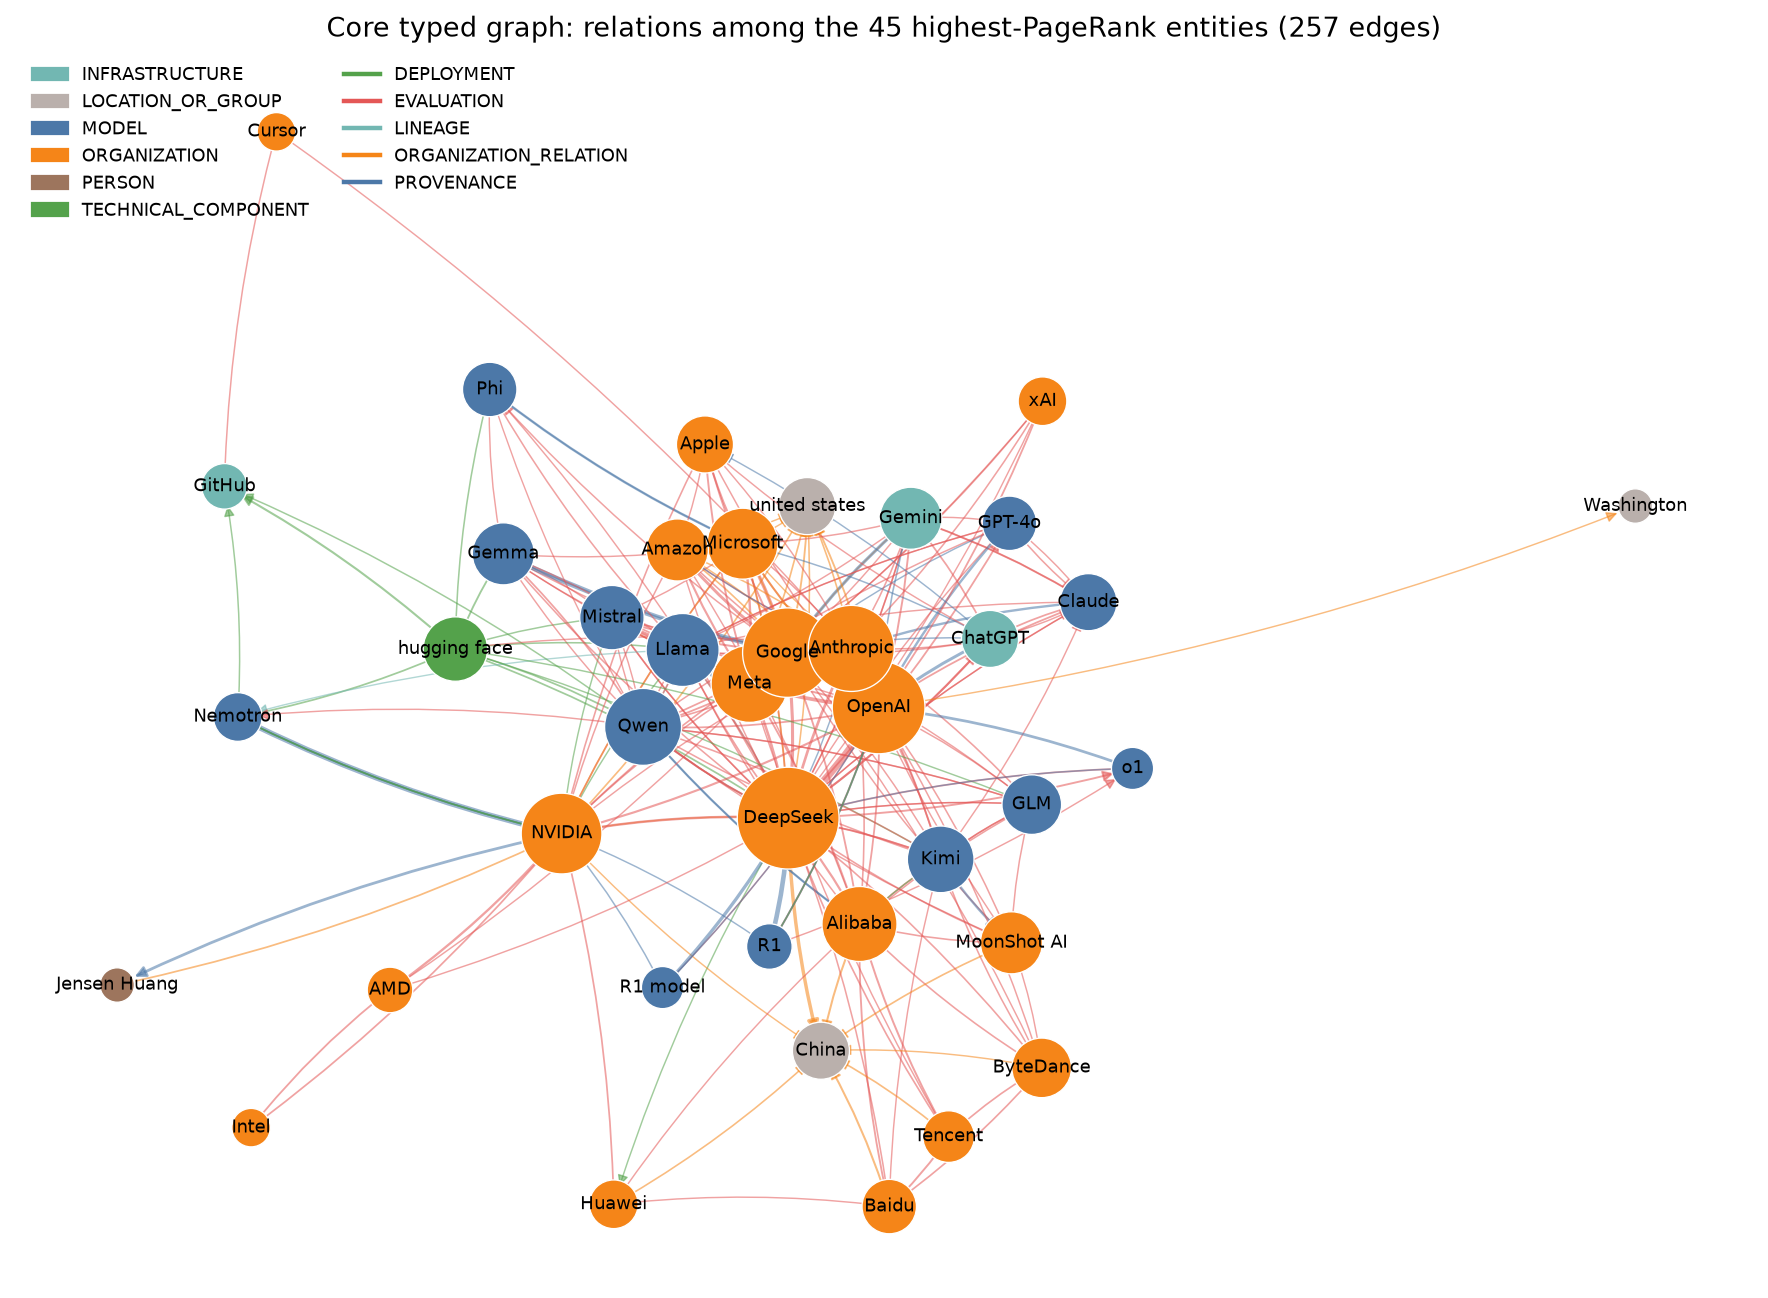

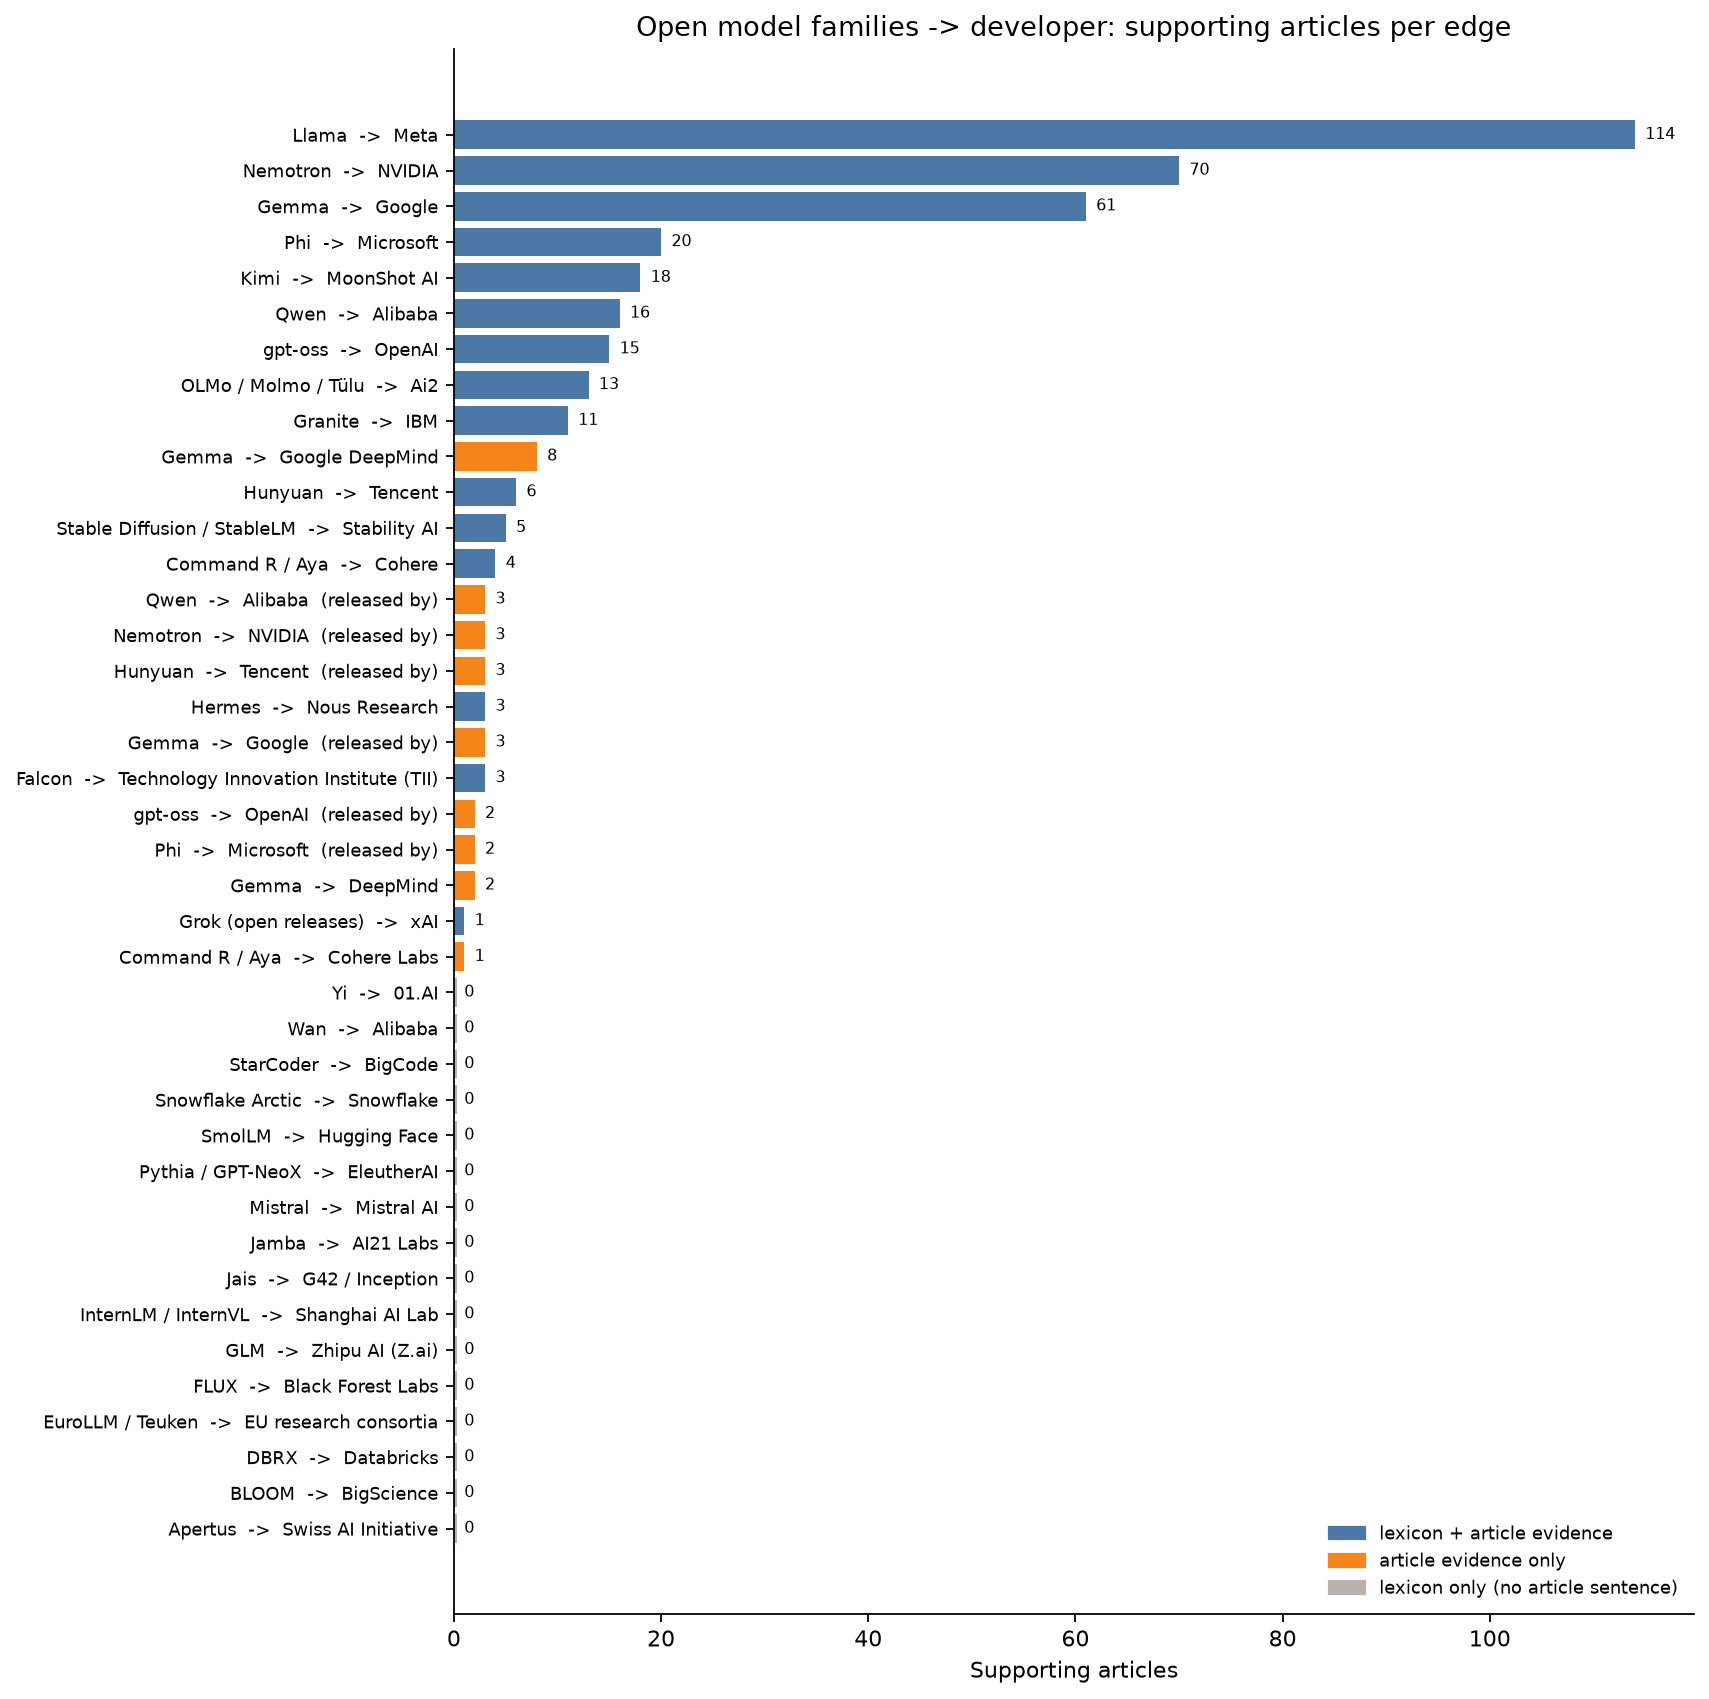

,근거 유형,edge 수
0,lexicon only (no article sentence),16
1,lexicon + article evidence,15
2,article evidence only,9


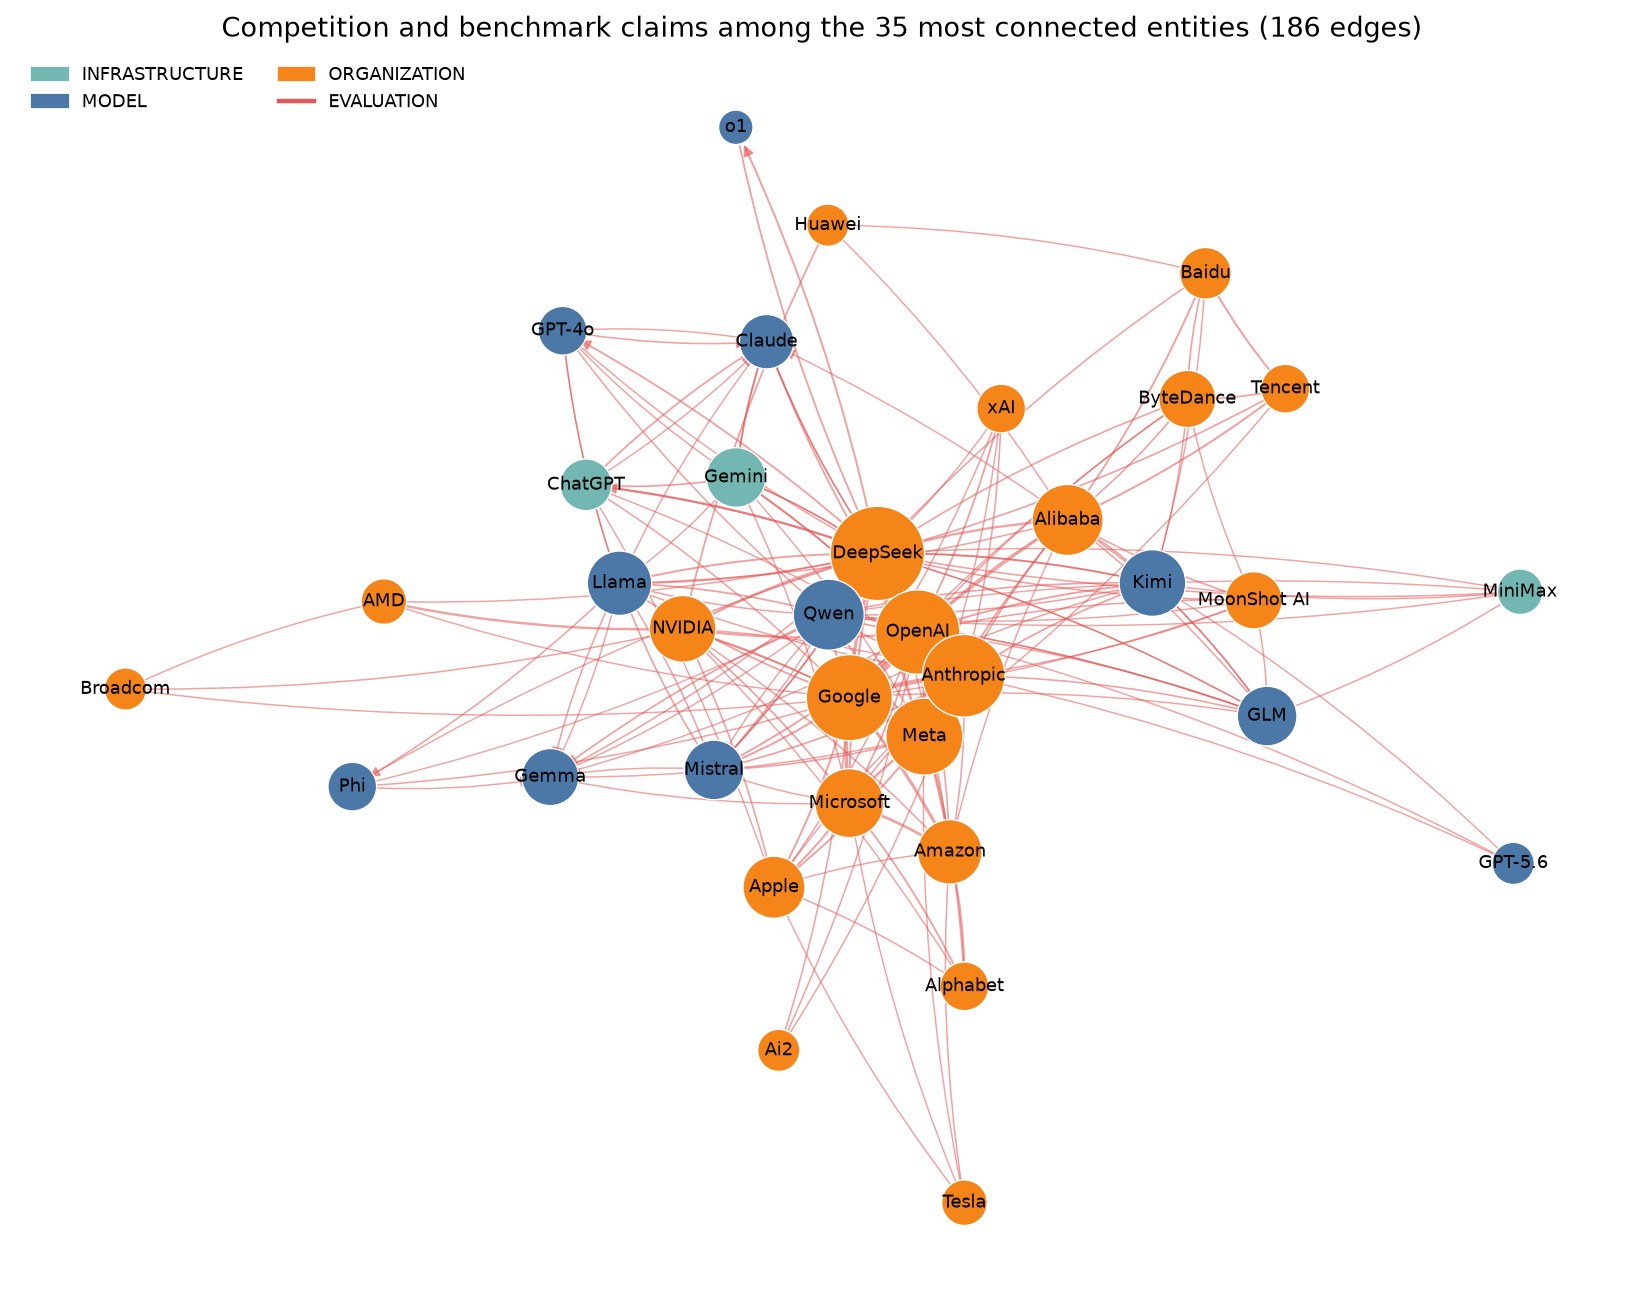

In [21]:
def draw_typed_subgraph(edges, title, filename, max_labels=40, figsize=(14, 10), k=None):
    graph = nx.MultiDiGraph()
    for row in edges.itertuples(index=False):
        for entity_id in (row.subject_id, row.object_id):
            graph.add_node(entity_id, label=labels[entity_id],
                           compact=node_index.loc[entity_id, "entity_type_compact"])
        graph.add_edge(row.subject_id, row.object_id, key=row.predicate, group=row.predicate_group,
                       weight=row.weight, directed=row.directed, sources=row.sources)
    simple = nx.Graph(graph.to_undirected())
    positions = nx.spring_layout(simple, seed=SEED, k=k or 1.6 / np.sqrt(len(simple)), iterations=400)
    fig, ax = plt.subplots(figsize=figsize)
    max_weight = max(d["weight"] for _, _, d in graph.edges(data=True))
    for source, target, data in graph.edges(data=True):
        nx.draw_networkx_edges(
            graph, positions, edgelist=[(source, target)], ax=ax, width=0.6 + 3.0 * data["weight"] / max_weight,
            edge_color=GROUP_COLORS.get(data["group"], "#6B7280"), alpha=0.55,
            style="solid" if "glirel" in data["sources"] else "dashed",
            arrows=True, arrowstyle="-|>" if data["directed"] else "-", arrowsize=10,
            connectionstyle="arc3,rad=0.06", node_size=300)
    degree = dict(simple.degree())
    nx.draw_networkx_nodes(graph, positions, ax=ax, linewidths=0.6, edgecolors="white",
                           node_color=[COMPACT_COLORS[graph.nodes[n]["compact"]] for n in graph],
                           node_size=[180 + 60 * degree[n] for n in graph])
    shown = sorted(graph, key=lambda n: -degree[n])[:max_labels]
    nx.draw_networkx_labels(graph, positions, labels={n: pretty(graph.nodes[n]["label"]) for n in shown}, font_size=8, ax=ax)
    groups = sorted({d["group"] for _, _, d in graph.edges(data=True)})
    types = sorted({graph.nodes[n]["compact"] for n in graph})
    handles = ([Patch(color=COMPACT_COLORS[t], label=t) for t in types]
               + [Line2D([0], [0], color=GROUP_COLORS[g], lw=2, label=g) for g in groups])
    ax.legend(handles=handles, loc="upper left", frameon=False, fontsize=8, ncol=2)
    ax.set_title(title)
    ax.axis("off")
    save_figure(fig, filename)

core_ids = set(typed_metrics.head(45)["entity_id"])
core_edges = collapsed_analysis[collapsed_analysis["subject_id"].isin(core_ids) & collapsed_analysis["object_id"].isin(core_ids)]
draw_typed_subgraph(core_edges, f"Core typed graph: relations among the 45 highest-PageRank entities ({len(core_edges)} edges)",
                    "06_core_typed_graph.png")

family_ids = set(nodes_kg.loc[nodes_kg["is_open_model_family"], "entity_id"])
family_edges = collapsed[collapsed["subject_id"].isin(family_ids)
                         & collapsed["predicate"].isin(["developed by", "released by"])]
# Family -> developer pairs are mostly disconnected, so a ranked bar chart is clearer than a network layout.
family_plot = family_edges.assign(
    pair=family_edges["subject_id"].map(labels).map(pretty) + "  ->  " + family_edges["object_id"].map(labels).map(pretty)
         + np.where(family_edges["predicate"].eq("released by"), "  (released by)", ""),
    evidence=np.select(
        [family_edges["sources"].str.contains("glirel") & family_edges["sources"].str.contains("wp1_lexicon"),
         family_edges["sources"].str.contains("glirel")],
        ["lexicon + article evidence", "article evidence only"], default="lexicon only (no article sentence)"),
).sort_values(["document_count", "pair"]).reset_index(drop=True)
EVIDENCE_COLORS = {"lexicon + article evidence": "#4C78A8", "article evidence only": "#F58518",
                   "lexicon only (no article sentence)": "#BAB0AC"}
fig, ax = plt.subplots(figsize=(10, 0.28 * len(family_plot) + 1.5))
ax.barh(family_plot["pair"], family_plot["document_count"].clip(lower=0.3),
        color=family_plot["evidence"].map(EVIDENCE_COLORS))
for y, value in enumerate(family_plot["document_count"]):
    ax.text(value + 1, y, str(int(value)), va="center", fontsize=7)
ax.legend(handles=[Patch(color=c, label=l) for l, c in EVIDENCE_COLORS.items()], loc="lower right", frameon=False, fontsize=8)
ax.set(title="Open model families -> developer: supporting articles per edge", xlabel="Supporting articles", ylabel="")
ax.tick_params(axis="y", labelsize=8)
save_figure(fig, "07_family_developer_edges.png")
display(family_plot["evidence"].value_counts().rename_axis("근거 유형").reset_index(name="edge 수"))

compete = collapsed[collapsed["predicate"].isin(["competes with", "outperforms"])]
compete_ids = set(pd.concat([compete["subject_id"], compete["object_id"]]).value_counts().head(35).index)
compete = compete[compete["subject_id"].isin(compete_ids) & compete["object_id"].isin(compete_ids)]
draw_typed_subgraph(compete, f"Competition and benchmark claims among the 35 most connected entities ({len(compete)} edges)",
                    "08_competition_graph.png", figsize=(13, 10))

## 12. Insight 후보와 근거 문장

graph pattern을 insight로 쓰기 전에 원문 근거와 대조해야 한다. 아래 표는 graph에서 자동으로 고른
후보이며, 각 후보에 근거 기사 수와 대표 근거 문장(점수가 가장 높은 문장, 기사 발행일 포함)을 붙인다.
`review_status=pending_review`이므로 검토 전에는 확정된 결론이 아니다.

In [22]:
def evidence_examples(subject_id, predicate, object_id, n=1):
    rows = dated[(dated["subject_id"] == subject_id) & (dated["predicate"] == predicate) & (dated["object_id"] == object_id)]
    rows = rows.sort_values("rule_score", ascending=False).drop_duplicates("document_id").head(n)
    return " || ".join(f"[{r.published_at}] {str(r.evidence_text)[:220]}" for r in rows.itertuples(index=False))

findings = []
developers = relation_metrics[relation_metrics["predicate"] == "developed by"].nlargest(5, "in_degree")
for row in developers.itertuples(index=False):
    products = collapsed[(collapsed["predicate"] == "developed by") & (collapsed["object_id"] == row.entity_id)]
    top = products.nlargest(4, "document_count")
    findings.append({"finding_type": "developer_hub", "entity_or_edge": row.canonical_name,
                     "metric": f"developed by in-degree {int(row.in_degree)}",
                     "documents": int(products["document_count"].sum()),
                     "detail": ", ".join(top["subject_id"].map(labels)),
                     "evidence": evidence_examples(top.iloc[0]["subject_id"], "developed by", row.entity_id)})
for predicate in ["competes with", "outperforms"]:
    for row in collapsed[collapsed["predicate"] == predicate].nlargest(4, "document_count").itertuples(index=False):
        findings.append({"finding_type": f"strong_{predicate.replace(' ', '_')}",
                         "entity_or_edge": f"{labels[row.subject_id]} -> {predicate} -> {labels[row.object_id]}",
                         "metric": "supporting articles", "documents": int(row.document_count),
                         "detail": f"{row.first_seen} ~ {row.last_seen}",
                         "evidence": evidence_examples(row.subject_id, predicate, row.object_id)})
for row in emerging.nlargest(5, "document_count").itertuples(index=False):
    findings.append({"finding_type": "emerging_2026", "entity_or_edge": row.edge, "metric": "first seen",
                     "documents": int(row.document_count), "detail": row.first_seen,
                     "evidence": evidence_examples(row.subject_id, row.predicate, row.object_id)})
for row in shares.nlargest(3, "change_pp").itertuples():
    findings.append({"finding_type": "rising_entity", "entity_or_edge": row.canonical_name,
                     "metric": f"relation evidence share {row.change_pp:+.1f}pp (P2 - P1)", "documents": None,
                     "detail": row.entity_type_compact, "evidence": ""})
finding_candidates = pd.DataFrame(findings).assign(review_status="pending_review")
with pd.option_context("display.max_colwidth", 160):
    display(finding_candidates)

,finding_type,entity_or_edge,metric,documents,detail,evidence,review_status
0,developer_hub,NVIDIA,developed by in-degree 80,307.0,"Nemotron, DGX Spark, NemoClaw, Blackwell architecture",[2025-08-14] NVIDIA-Nemotron-Nano-12B-v2-Base is a large language model (LLM) developed by NVIDIA that is designed as a completion model for a given piece o...,pending_review
1,developer_hub,Google,developed by in-degree 60,236.0,"Gemma, Gemini, ML Pathways, TPUs","[2026-06-10] Developed by Google DeepMind, DiffusionGemma undergoes the same rigorous safety evaluations as our proprietary Gemini models.",pending_review
2,developer_hub,OpenAI,developed by in-degree 49,329.0,"ChatGPT, GPT-5, o1, GPT-4",[2025-03-19] OpenAI has developed ChatGPT into one of the prominent alternatives to Le Chat.,pending_review
3,developer_hub,Anthropic,developed by in-degree 22,83.0,"Claude, MCP, Sonnet, Claude Code","[2026-03-25] Claude can now use your computer (Activity: 2106): Claude, an AI developed by Anthropic, is now capable of using your computer to perform tasks...",pending_review
4,developer_hub,DeepSeek,developed by in-degree 17,149.0,"R1, R1 model, Chinese AI, V3","[2025-01-27] The model was developed by the Chinese AI startup DeepSeek, which claims that R1 matches or even surpasses OpenAI’s ChatGPT o1 on multiple key ...",pending_review
5,strong_competes_with,DeepSeek -> competes with -> OpenAI,supporting articles,103.0,2024-12-17 ~ 2026-08-11,[2024-12-17] DeepSeek said last month that its R1 model competes with OpenAI's o1 — a model designed for reasoning or solving more complex tasks.,pending_review
6,strong_competes_with,Anthropic -> competes with -> OpenAI,supporting articles,97.0,2024-09-25 ~ 2026-08-27,"[2026-01-15] The company is a public benefit corporation, like OpenAI and competitor Anthropic, which created Claude.",pending_review
7,strong_competes_with,Google -> competes with -> OpenAI,supporting articles,80.0,2024-09-25 ~ 2026-08-19,"[2025-01-30] This development intensifies the AI-generated media race, placing Google in competition with OpenAI’s Sora and other video synthesis models eme...",pending_review
8,strong_competes_with,Anthropic -> competes with -> Google,supporting articles,51.0,2024-09-25 ~ 2026-08-19,"[2026-07-09] Muse Spark 1.1 changes that equation by allowing developers to call Meta’s own hosted infrastructure via the new Meta Model API, putting the co...",pending_review
9,strong_outperforms,DeepSeek -> outperforms -> Llama,supporting articles,10.0,2025-01-15 ~ 2026-08-11,"[2025-01-15] In DeepSeek’s tests, DeepSeek-V3 outperformed Llama 3.1 405B and Qwen 2.5 72B across the board, and its performance compared favorably with tha...",pending_review


In [23]:
hub = finding_candidates[finding_candidates["finding_type"] == "developer_hub"].iloc[0]
rivals = finding_candidates[finding_candidates["finding_type"] == "strong_competes_with"].head(3)
deepseek = shares.loc["org:deepseek"] if "org:deepseek" in shares.index else None
sizes = nodes_kg.set_index("canonical_name")["parameter_sizes_b"]
size_text = "; ".join(f"{name} {', '.join(f'{v:g}B' for v in json.loads(sizes[name]))}"
                      for name in ["Llama", "Qwen", "Gemma", "gpt-oss"] if name in sizes and sizes[name])
display(Markdown(f'''
### 핵심 insight 초안 (검토 전)

각 항목은 관찰 → 사용한 graph·지표 → 근거 → 한계 순서로 적었다. 위 후보 표의 근거 문장을 원문과 대조한 뒤 확정한다.

**1. 오픈 모델 담론의 중심이 Llama에서 중국 family와 Nemotron으로 분산되었다.**
10절 family 기사 비율({first_q} → {last_q}): Llama {fs.loc["Llama", first_q]:.0%} → {fs.loc["Llama", last_q]:.0%}, Qwen {fs.loc["Qwen", last_q]:.0%},
Kimi {fs.loc["Kimi", last_q]:.0%}, GLM {fs.loc["GLM", last_q]:.0%}({last_q}).
한계: 언급 비율은 실제 사용량이나 성능이 아니라 기사 노출이다.

**2. {hub["entity_or_edge"]}는 typed graph에서 가장 많은 개발 산출물과 연결된다** ({hub["metric"]}; 예: {hub["detail"]}).
하드웨어·모델·agent 소프트웨어에 걸쳐 있고, 2026년에 처음 관찰된 relation에도 이 회사의 제품이 많다.

**3. 경쟁 관계는 소수의 frontier 기업을 중심으로 형성된다**:
{"; ".join(f"{r['entity_or_edge']} ({int(r['documents'])}개 기사)" for _, r in rivals.iterrows())}.
한계: 여러 회사를 나열한 문장에서 추출된 경쟁 관계가 섞여 있다.

**4. {peak_quarter} 보도 집중이 전체 graph 구조에 큰 영향을 준다.**
{f"DeepSeek의 relation 근거 기사 비중은 P1 {deepseek[p1]:.0%} → P2 {deepseek[p2]:.0%}이다. " if deepseek is not None else ""}전체 기간을 합친
centrality는 이 분기의 영향을 크게 받으므로 기간별 지표와 함께 해석해야 한다.

**5. 기사에서 관찰된 모델 규모** (3-1절 규칙 기반 속성, 근거 문장 2개 이상): {size_text}.
family 단위로 모은 값이므로 어느 버전의 크기인지는 `model_attribute_evidence`의 근거 문장(`surface`)으로 확인한다.

**insight로 쓰지 않는 것**: `outperforms` relation은 "it outperforms Qwen 2.5, Gemma 3 and Llama 3"처럼 제3의 모델이
둘 다를 능가한다는 서술에서 잘못 추출된 경우가 많아, 사람 검수 전까지 insight에서 제외한다.
'''))


### 핵심 insight 초안 (검토 전)

각 항목은 관찰 → 사용한 graph·지표 → 근거 → 한계 순서로 적었다. 위 후보 표의 근거 문장을 원문과 대조한 뒤 확정한다.

**1. 오픈 모델 담론의 중심이 Llama에서 중국 family와 Nemotron으로 분산되었다.**
10절 family 기사 비율(2024Q4 → 2026Q3): Llama 65% → 19%, Qwen 32%,
Kimi 40%, GLM 27%(2026Q3).
한계: 언급 비율은 실제 사용량이나 성능이 아니라 기사 노출이다.

**2. NVIDIA는 typed graph에서 가장 많은 개발 산출물과 연결된다** (developed by in-degree 80; 예: Nemotron, DGX Spark, NemoClaw, Blackwell architecture).
하드웨어·모델·agent 소프트웨어에 걸쳐 있고, 2026년에 처음 관찰된 relation에도 이 회사의 제품이 많다.

**3. 경쟁 관계는 소수의 frontier 기업을 중심으로 형성된다**:
DeepSeek -> competes with -> OpenAI (103개 기사); Anthropic -> competes with -> OpenAI (97개 기사); Google -> competes with -> OpenAI (80개 기사).
한계: 여러 회사를 나열한 문장에서 추출된 경쟁 관계가 섞여 있다.

**4. 2025Q1 보도 집중이 전체 graph 구조에 큰 영향을 준다.**
DeepSeek의 relation 근거 기사 비중은 P1 42% → P2 14%이다. 전체 기간을 합친
centrality는 이 분기의 영향을 크게 받으므로 기간별 지표와 함께 해석해야 한다.

**5. 기사에서 관찰된 모델 규모** (3-1절 규칙 기반 속성, 근거 문장 2개 이상): Llama 1B, 3B, 7B, 8B, 11B, 13B, 70B, 90B, 400B, 405B, 2000B; Qwen 0.6B, 0.8B, 1.5B, 1.7B, 2B, 3B, 4B, 7B, 8B, 9B, 14B, 27B, 30B, 32B, 35B, 72B, 80B, 235B, 397B, 480B; Gemma 1B, 2B, 3B, 4B, 7B, 9B, 12B, 26B, 27B, 31B; gpt-oss 20B, 120B.
family 단위로 모은 값이므로 어느 버전의 크기인지는 `model_attribute_evidence`의 근거 문장(`surface`)으로 확인한다.

**insight로 쓰지 않는 것**: `outperforms` relation은 "it outperforms Qwen 2.5, Gemma 3 and Llama 3"처럼 제3의 모델이
둘 다를 능가한다는 서술에서 잘못 추출된 경우가 많아, 사람 검수 전까지 insight에서 제외한다.


## 13. 한계와 타당성 위협

- **Tier B precision 미확인**: 보정 전 표본의 precision은 AI 초안 기준 약 0.47, 단어 목록 필터 후
  약 0.71이었다. 보정 규칙의 효과는 새 Tier B 표본 90개의 사람 검수로만 확정할 수 있다. 그 전까지
  graph 상태는 `candidate_pending_human_review`다.
- **Tier A는 기사 근거가 없다**: WP1 lexicon의 curated relation이다. Stage 3에서 기사 근거가 필요한
  답변에는 Tier B assertion만 인용한다.
- **날짜 의미**: 모든 날짜는 기사 발행일이다. 출시일이나 사건 발생일로 표현하지 않는다.
- **관계의 유효 기간은 다루지 않는다**: relation은 기사에서 관찰된 시점의 기록(`first_seen`, `last_seen`, 근거별
  `published_at`)이며 언제까지 사실인지를 뜻하지 않는다. `last_seen` 이후 보도가 없다고 관계가 끝났다는 뜻은 아니고,
  "가장 큰 모델", "최고 성능"처럼 새 모델이 나오면 바뀌는 주장도 당시 기사 기준이다. 시점이 중요한 질문은 Stage 3에서
  근거 날짜로 거르고 최신 근거를 우선해 답한다.
- **co-occurrence ≠ 의미 관계**: 같은 문장에 함께 등장했다는 뜻일 뿐, 경쟁·협력·인과를 뜻하지 않는다.
  병합 node 쌍의 문서 수는 상한값이다.
- **중심성 ≠ 산업 영향력**: 1,210개 Open Models 기사에서의 언급·관계 구조다. 보정 전 graph의 민감도
  분석에서 score와 threshold에 따라 순위가 크게 바뀌었다.
- **일반명사 규칙과 별칭 표의 한계**: 규칙이 놓친 일반명사(예: `Fox`, `Nari`)와 등록되지 않은 별칭이
  남아 있을 수 있다. `outputs/stage1_wp3_relation_correction_20261008/corrections/`를 검토해 보완한다.
- **family 단위 축약**: `MedGemma` → `Gemma`, `Mixtral` → `Mistral`처럼 WP1 lexicon이 family 단위로
  묶으므로 같은 family 안의 버전 간 계보(`Llama 4 Behemoth` → `Llama 4 Maverick`)는 표현할 수 없다. 파라미터 수와
  context window는 3-1절에서 family node에 붙였지만, 어느 버전의 값인지는 근거 문장(`surface`)에서 확인해야 한다.
- **회사이자 모델인 node**: `DeepSeek`처럼 WP1 family이면서 회사로 분류된 node는 3-1절에서 모델 자리의 relation도
  받으므로 한 node가 두 역할을 한다. relation별 표에서 `entity_type`이 COMPANY로 보이는 모델 relation은 이 때문이다.
- **보조 층(Tier C)**: 3-1절의 계보·속성·학습 relation 중 일부는 근거 문장이 1개뿐이다. 보조 검수 표본으로 정확도를
  확인하기 전에는 낮은 신뢰도의 relation으로 다룬다.

## 14. 저장과 재로딩 검증

Stage 3에서 다시 쓰도록 graph와 schema를 저장한다.

- **Parquet**: 기계가 읽는 기준 파일. CSV는 사람이 확인하기 위한 사본
- **GraphML**: Gephi·Cytoscape 등 외부 도구용. list 속성은 JSON 문자열로 저장
- **node-link JSON**: NetworkX와 Stage 3 코드에서 바로 로드
- `graph_schema.json`, `DATA_DICTIONARY_KO.md`, `run_manifest.json`

대용량 파일은 `outputs/stage1_wp3_knowledge_graph_ko/`(Git 제외)에, 작은 schema·요약·그림은
`artifacts/stage1_wp3/final_ko/`에 저장한다.

In [24]:
alias_names = wp2_nodes.set_index("entity_id")["entity"]
nodes_kg["aliases"] = [
    json.dumps(sorted({alias_names.get(i, "") for i in merged.split(" | ")} - {name, ""}), ensure_ascii=False)
    for merged, name in zip(nodes_kg["merged_ids"], nodes_kg["canonical_name"])
]
graph_node_ids = set(typed_graph) | set(cooccurrence_graph) | set(assertion_graph)
nodes_out = nodes_kg[nodes_kg["entity_id"].isin(graph_node_ids)].merge(
    typed_metrics[["entity_id", "pagerank", "betweenness", "weighted_degree"]].add_prefix("typed_")
    .rename(columns={"typed_entity_id": "entity_id"}), on="entity_id", how="left",
).merge(
    cooc_metrics[["entity_id", "pagerank", "betweenness", "clustering"]].add_prefix("cooc_")
    .rename(columns={"cooc_entity_id": "entity_id"}), on="entity_id", how="left",
).merge(community_members[["entity_id", "community_id"]], on="entity_id", how="left")

tables = {
    "nodes": nodes_out,
    "typed_edges_assertions": assertions,
    "typed_edges_collapsed": collapsed,
    "cooccurrence_edges": cooccurrence_edges,
    "node_metrics": pd.concat([typed_metrics, cooc_metrics], ignore_index=True),
    "relation_type_metrics": relation_metrics,
    "relation_type_summary": relation_summary,
    "node_communities": community_members,
    "community_summary": community_summary,
    "quarterly_relation_assertions": quarterly_assertions.reset_index(),
    "quarterly_new_typed_edges": quarterly_new_edges.reset_index(),
    "family_quarterly_share": family_share.reset_index(names="family"),
    "emerging_relations_2026": emerging,
    "entity_period_share": shares.reset_index(names="entity_id"),
    "graph_finding_candidates": finding_candidates,
    "model_attribute_evidence": attribute_evidence.drop(columns=["sentence_key"]),
}
for name, table in tables.items():
    table.to_parquet(FINAL_OUTPUT_DIR / f"{name}.parquet", index=False)
    table.to_csv(FINAL_OUTPUT_DIR / f"{name}.csv", index=False, encoding="utf-8-sig")

def graphml_safe(graph):
    safe = graph.copy()
    for _, data in safe.nodes(data=True):
        data.update({k: scalar(v) for k, v in data.items()})
    edge_data = safe.edges(keys=True, data=True) if safe.is_multigraph() else safe.edges(data=True)
    for *_, data in edge_data:
        data.update({k: scalar(v) for k, v in data.items()})
    return safe

for stem, graph in [("assertion_graph", assertion_graph), ("typed_graph", typed_graph),
                    ("cooccurrence_graph", cooccurrence_graph)]:
    nx.write_graphml(graphml_safe(graph), FINAL_OUTPUT_DIR / f"{stem}.graphml")
    (FINAL_OUTPUT_DIR / f"{stem}.json").write_text(
        json.dumps(nx.node_link_data(graphml_safe(graph), edges="edges"), ensure_ascii=False), encoding="utf-8")

summary = {
    "schema_version": graph_schema["schema_version"], "status": GRAPH_STATUS,
    "created_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "graphs": {name: graph_summary(graph) for name, graph in
               [("assertion", assertion_graph), ("typed", typed_graph), ("cooccurrence", cooccurrence_graph)]},
    "relation_types": int(collapsed["predicate"].nunique()),
    "tiers": collapsed["tier"].value_counts().to_dict(),
    "review": {"reviewed_rows": int(review_labels.notna().sum()),
               "precision": None if np.isnan(review_precision) else float(review_precision)},
    "cooccurrence_minimum_documents": MIN_COOCCURRENCE_DOCUMENTS,
    "communities": int(len(community_summary)), "modularity": round(float(modularity), 4),
}
sha256 = lambda path: hashlib.sha256(Path(path).read_bytes()).hexdigest()
manifest = {
    **summary,
    "inputs": {str(p.relative_to(ROOT)): sha256(p) for p in [
        WP2_INPUT_DIR / "nodes.csv", WP2_INPUT_DIR / "relations_evidence.csv",
        WP2_INPUT_DIR / "edges_cooccurrence.csv", CORRECTION_DIR / "edges_graph_candidates.csv",
        CORRECTION_DIR / "nodes_corrected.csv", CORRECTED_REVIEW_PATH]},
    "versions": {"networkx": nx.__version__, "pandas": pd.__version__},
}
for directory in [FINAL_OUTPUT_DIR, FINAL_ARTIFACT_DIR]:
    (directory / "graph_schema.json").write_text(json.dumps(graph_schema, ensure_ascii=False, indent=2), encoding="utf-8")
    (directory / "graph_summary.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8")
(FINAL_OUTPUT_DIR / "run_manifest.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8")
for small in ["typed_edges_collapsed", "relation_type_summary", "community_summary", "graph_finding_candidates"]:
    tables[small].to_csv(FINAL_ARTIFACT_DIR / f"{small}.csv", index=False, encoding="utf-8-sig")

# Re-load check: the saved files must reproduce the in-memory graphs
reloaded = {
    "typed_graph.graphml": nx.read_graphml(FINAL_OUTPUT_DIR / "typed_graph.graphml"),
    "typed_graph.json": nx.node_link_graph(json.loads((FINAL_OUTPUT_DIR / "typed_graph.json").read_text(encoding="utf-8")), edges="edges"),
    "cooccurrence_graph.graphml": nx.read_graphml(FINAL_OUTPUT_DIR / "cooccurrence_graph.graphml"),
    "assertion_graph.json": nx.node_link_graph(json.loads((FINAL_OUTPUT_DIR / "assertion_graph.json").read_text(encoding="utf-8")), edges="edges"),
}
expected = {"typed": typed_graph, "cooccurrence": cooccurrence_graph, "assertion": assertion_graph}
reload_check = pd.DataFrame([
    (name, g.number_of_nodes(), g.number_of_edges(),
     (g.number_of_nodes(), g.number_of_edges()) == (expected[name.split("_")[0]].number_of_nodes(),
                                                   expected[name.split("_")[0]].number_of_edges()))
    for name, g in reloaded.items()
], columns=["file", "node", "edge", "일치"])
display(reload_check)
assert reload_check["일치"].all()
print(sorted(p.name for p in FINAL_OUTPUT_DIR.iterdir())[:40])

,file,node,edge,일치
0,typed_graph.graphml,1082,1486,True
1,typed_graph.json,1082,1486,True
2,cooccurrence_graph.graphml,4858,23226,True
3,assertion_graph.json,1082,8322,True


['DATA_DICTIONARY_KO.md', 'assertion_graph.graphml', 'assertion_graph.json', 'community_summary.csv', 'community_summary.parquet', 'cooccurrence_edges.csv', 'cooccurrence_edges.parquet', 'cooccurrence_graph.graphml', 'cooccurrence_graph.json', 'emerging_relations_2026.csv', 'emerging_relations_2026.parquet', 'entity_period_share.csv', 'entity_period_share.parquet', 'family_quarterly_share.csv', 'family_quarterly_share.parquet', 'graph_finding_candidates.csv', 'graph_finding_candidates.parquet', 'graph_schema.json', 'graph_summary.json', 'model_attribute_evidence.csv', 'model_attribute_evidence.parquet', 'node_communities.csv', 'node_communities.parquet', 'node_metrics.csv', 'node_metrics.parquet', 'nodes.csv', 'nodes.parquet', 'quarterly_new_typed_edges.csv', 'quarterly_new_typed_edges.parquet', 'quarterly_relation_assertions.csv', 'quarterly_relation_assertions.parquet', 'relation_type_metrics.csv', 'relation_type_metrics.parquet', 'relation_type_summary.csv', 'relation_type_summary.p

In [25]:
DATA_DICTIONARY = f'''# Stage 1 WP3 최종 지식그래프 데이터 사전

Schema: `{graph_schema["schema_version"]}` · 상태: `{GRAPH_STATUS}` · Track: Open Models
날짜(`published_at`, `first_seen`, `last_seen`)는 모두 **기사 발행일**이다.

## Node (`nodes.*`)
| 열 | 설명 |
|---|---|
| `entity_id` | 보정 후 node ID. 별칭·이름 변형이 합쳐진 원래 WP2 ID는 `merged_ids` |
| `canonical_name`, `aliases` | 대표 이름과 병합된 다른 이름(JSON list) |
| `entity_type` / `entity_type_compact` | WP2 type / 9개 compact type |
| `mention_count`, `document_count` | 언급 수 / 언급 기사 수 |
| `is_open_model_family` | WP1 lexicon의 open model family 여부 |
| `parameter_sizes_b`, `context_windows_tokens` | 기사에서 관찰된 파라미터 크기(B)와 context window(토큰) 목록(JSON). 3-1절 규칙 기반 추출, 근거 문장 2개 이상 |
| `typed_*`, `cooc_*`, `community_id` | typed·co-occurrence graph metric과 community |

## Typed edge
- `typed_edges_assertions.*`: 근거 문장 1개당 1행. `relation_id`, `subject_id`, `predicate`, `object_id`,
  `document_id`, `text_unit_id`(= `doc_id:sentence_id`), `evidence_text`, `published_at`, `extraction_method`
  (`glirel`, `wp1_lexicon`, `rule_attribute`), `rule_score`
- `typed_edges_collapsed.*`: unique triple 1개당 1행. `evidence_count`, `document_count`(edge weight),
  `n_distinct_sentences`, `first_seen`, `last_seen`, `tier`(A: lexicon, B: 근거 문장 2개 이상, C: 근거 1개인 계보·속성·학습 보조 층),
  `sources`, `added_by`(보정 / 관계 기준 type / 보조 층 / 규칙 기반 속성), `review_status`,
  `predicate_group`, `directed`, `relation_ids`/`text_unit_ids`(JSON list)

## Co-occurrence edge (`cooccurrence_edges.*`)
같은 문장에 함께 언급된 entity 쌍. `sentence_count`, `document_count`(문서 {MIN_COOCCURRENCE_DOCUMENTS}개 이상),
`npmi`, `merged_pairs`(보정으로 합쳐진 원래 쌍 수). 의미 관계가 아니다.

## Graph 파일
`assertion_graph`, `typed_graph`, `cooccurrence_graph` 각각 `.graphml`과 node-link `.json`

## 분석 표
`node_metrics`, `relation_type_metrics`, `relation_type_summary`, `node_communities`, `community_summary`,
`quarterly_relation_assertions`, `quarterly_new_typed_edges`, `family_quarterly_share`,
`emerging_relations_2026`, `entity_period_share`, `graph_finding_candidates`(검토 전 후보),
`model_attribute_evidence`(규칙 기반 속성의 근거 문장 전체: family, 값, 원문 표현 `surface`, 적용 규칙)

## Stage 3 provenance
`entity_id` → `relation_id` → `text_unit_id` → `document_id` → `published_at`.
기사 제목·URL은 WP1 `open_models_core.parquet`의 `doc_id`로 연결한다.
'''
for directory in [FINAL_OUTPUT_DIR, FINAL_ARTIFACT_DIR]:
    (directory / "DATA_DICTIONARY_KO.md").write_text(DATA_DICTIONARY, encoding="utf-8")
print(DATA_DICTIONARY[:600])

# Stage 1 WP3 최종 지식그래프 데이터 사전

Schema: `stage1-wp3-open-models-kg-v1.0` · 상태: `candidate_pending_human_review` · Track: Open Models
날짜(`published_at`, `first_seen`, `last_seen`)는 모두 **기사 발행일**이다.

## Node (`nodes.*`)
| 열 | 설명 |
|---|---|
| `entity_id` | 보정 후 node ID. 별칭·이름 변형이 합쳐진 원래 WP2 ID는 `merged_ids` |
| `canonical_name`, `aliases` | 대표 이름과 병합된 다른 이름(JSON list) |
| `entity_type` / `entity_type_compact` | WP2 type / 9개 compact type |
| `mention_count`, `document_count` | 언급 수 / 언급 기사 수 |
| `is_open_model_family` | WP1 lexicon의 open model family 여부 |
| `parameter_sizes_b`, `context_windows_t


## 15. Stage 3 Graph-RAG 연결 smoke test

저장한 graph를 기존 `GraphEvidenceRetriever`로 다시 읽어, 질문 속 entity → typed edge → 근거 문장 →
기사 ID·발행일로 돌아갈 수 있는지 확인한다. WP1 `open_models_core.parquet`이 있으면 기사 제목과 URL도
붙인다.

In [26]:
text_units = pd.DataFrame({
    "text_unit_id": text_unit(sentences["doc_id"], sentences["sentence_id"]),
    "document_id": sentences["doc_id"],
    "text_unit_text": sentences["sentence_text"],
})
documents = (assertions.dropna(subset=["document_id"]).groupby("document_id")["published_at"].first()
             .reset_index())
if WP1_CORE_PATH.exists():
    wp1_documents = pd.read_parquet(WP1_CORE_PATH, columns=["doc_id", "title", "url"])
    documents = documents.merge(wp1_documents.rename(columns={"doc_id": "document_id"}), on="document_id", how="left")

retriever = GraphEvidenceRetriever(
    nodes=pd.read_parquet(FINAL_OUTPUT_DIR / "nodes.parquet"),
    assertions=pd.read_parquet(FINAL_OUTPUT_DIR / "typed_edges_assertions.parquet").dropna(subset=["text_unit_id"]),
    text_units=text_units,
    documents=documents,
)
smoke_queries = [
    ("Who developed Qwen?", ["developed by"]),
    ("Which companies compete with DeepSeek?", ["competes with"]),
    ("What does NVIDIA manufacture?", ["manufactured by"]),
]
smoke_rows = []
for query, predicates in smoke_queries:
    result = retriever.retrieve(query, predicates=predicates, top_k=3)
    for item in result["evidence"]:
        smoke_rows.append({"query": query, "subject": item["subject"]["name"], "predicate": item["predicate"],
                           "object": item["object"]["name"], "published_at": item["published_at"],
                           "document_id": item["document_id"], "passage": str(item["passage"])[:160]})
    assert result["evidence"], f"no evidence returned for: {query}"
smoke_test = pd.DataFrame(smoke_rows)
with pd.option_context("display.max_colwidth", 160):
    display(smoke_test)

,query,subject,predicate,object,published_at,document_id,passage
0,Who developed Qwen?,Qwen,developed by,Alibaba,2024-12-03,doc_d95ddd7d2b,"Part of the underlying AI for GeoGPT is Qwen, a large language model built by the Chinese tech company Alibaba."
1,Who developed Qwen?,Qwen,developed by,Alibaba,2025-05-30,doc_3ac75461e8,"Built upon Alibaba’s Qwen3-8B model, this version achieves superior performance on benchmarks like AIME 2025 and HMMT, rivalling models such as Google’s Gem..."
2,Who developed Qwen?,Qwen,developed by,Alibaba,2026-07-09,doc_a423077f94,"Alibaba’s newer proprietary API model, Qwen 3.7 Max, supports a 1-million-token context and is designed for agent-based workloads."
3,Which companies compete with DeepSeek?,DeepSeek,competes with,OpenAI,2024-12-17,doc_5eb8fa495f,DeepSeek said last month that its R1 model competes with OpenAI's o1 — a model designed for reasoning or solving more complex tasks.
4,Which companies compete with DeepSeek?,o1,competes with,DeepSeek,2024-12-17,doc_5eb8fa495f,DeepSeek said last month that its R1 model competes with OpenAI's o1 — a model designed for reasoning or solving more complex tasks.
5,Which companies compete with DeepSeek?,DeepSeek,competes with,ChatGPT,2025-01-29,doc_db0d18d9a5,DeepSeek’s own chatbot — a ChatGPT rival — has also risen to become the top free app in Apple’s app store.
6,What does NVIDIA manufacture?,H100,manufactured by,NVIDIA,2024-11-13,doc_a807f75249,"For certain parts of transformer neural networks such as ChatGPT, Llama2, and Stable Diffusion, the Nvidia H100 and H200 use 8-bit floating point numbers."
7,What does NVIDIA manufacture?,H200,manufactured by,NVIDIA,2024-11-13,doc_a807f75249,"For certain parts of transformer neural networks such as ChatGPT, Llama2, and Stable Diffusion, the Nvidia H100 and H200 use 8-bit floating point numbers."
8,What does NVIDIA manufacture?,RTX 6000 Pro,manufactured by,NVIDIA,2026-03-25,doc_b2d9110022,Daemontatox points out that the issue with NVIDIA’s RTX 6000 Pro being marketed as ‘ Blackwell’ is more related to the Streaming Multiprocessor (SM) archite...


## 16. WP3 요구사항 확인

과제 안내서의 Knowledge Graph Construction 요구사항을 기준으로 자동 확인 결과와 사람이 확인해야 할 항목을
구분한다. `PENDING`은 코드로 확정할 수 없는 검토 항목이다.

In [27]:
figure_files = sorted(p.name for p in FIGURE_DIR.glob("*.png"))
checklist = pd.DataFrame(
    [
        ("compact topic-specific schema를 graph 전에 정의", "PASS", f"{len(graph_schema['entity_types'])} node type, "
         f"{len(graph_schema['relation_types'])} relation type, graph_schema.json"),
        ("node = entity, edge = co-mention 또는 extracted relation", "PASS",
         f"typed {typed_graph.number_of_edges():,} / co-occurrence {cooccurrence_graph.number_of_edges():,} edge"),
        ("모든 edge endpoint가 node table에 존재", "PASS" if graph_node_ids <= set(nodes_out["entity_id"]) else "FAIL", "nodes.parquet"),
        ("centrality 분석", "PASS", "weighted degree, PageRank, betweenness, relation별 in/out degree"),
        ("clustering·community 분석", "PASS", f"{len(community_summary)} communities, modularity {modularity:.3f}"),
        ("시간 분석 (emerging relationship)", "PASS", f"분기별 relation, family 추이, 2026년 신규 triple {len(emerging)}개"),
        ("NetworkX 시각화와 legend", "PASS", f"{len(figure_files)}개 그림"),
        ("graph와 schema 저장·재로딩", "PASS" if reload_check["일치"].all() else "FAIL", "GraphML, node-link JSON, Parquet"),
        ("short schema / data dictionary", "PASS", "DATA_DICTIONARY_KO.md"),
        ("Stage 3 provenance smoke test", "PASS" if len(smoke_test) else "FAIL", f"{len(smoke_test)}개 근거 반환"),
        ("Tier B relation 사람 검수 90개, precision >= 0.80", "PASS" if GRAPH_STATUS == "human_validated_sample" else "PENDING",
         f"검수 {int(review_labels.notna().sum())}/90"),
        ("insight를 원문 근거와 대조해 확정", "PENDING", "graph_finding_candidates 원문 대조"),
        ("그림 label·legend·threshold 사람 승인", "PENDING", ", ".join(figure_files)),
    ],
    columns=["요구사항", "상태", "근거"],
)
display(checklist)
assert not checklist["상태"].eq("FAIL").any()

,요구사항,상태,근거
0,compact topic-specific schema를 graph 전에 정의,PASS,"9 node type, 31 relation type, graph_schema.json"
1,"node = entity, edge = co-mention 또는 extracted ...",PASS,"typed 1,486 / co-occurrence 23,226 edge"
2,모든 edge endpoint가 node table에 존재,PASS,nodes.parquet
3,centrality 분석,PASS,"weighted degree, PageRank, betweenness, relati..."
4,clustering·community 분석,PASS,"192 communities, modularity 0.236"
5,시간 분석 (emerging relationship),PASS,"분기별 relation, family 추이, 2026년 신규 triple 122개"
6,NetworkX 시각화와 legend,PASS,8개 그림
7,graph와 schema 저장·재로딩,PASS,"GraphML, node-link JSON, Parquet"
8,short schema / data dictionary,PASS,DATA_DICTIONARY_KO.md
9,Stage 3 provenance smoke test,PASS,9개 근거 반환
